# Notebook 04: Luật kết hợp theo cụm và gợi ý sản phẩm giữ chân khách hàng

**Mục tiêu của notebook:**

1. Tìm **luật kết hợp** (sản phẩm hay được mua cùng nhau) **riêng cho từng cụm khách hàng** bằng thuật toán **FP-Growth**.
2. So sánh hành vi mua kèm giữa các cụm (VIP mua kèm gì, khác cụm Có nguy cơ thế nào).
3. **Gợi ý sản phẩm** cho các khách có nguy cơ rời bỏ cao (từ notebook 03), dựa trên sản phẩm khách đã mua: ưu tiên luật của cụm mà khách thuộc về, sau đó đến luật mua kèm của toàn cửa hàng, cuối cùng mới đến hàng bán chạy. **Mỗi gợi ý đều kèm lý do bằng lời.**
4. Tổng hợp **đề xuất chiến lược** cho từng cụm, kèm căn cứ số liệu cho từng hành động.

**Đầu vào:** `transactions_clean.csv`, `customers_clustered.csv`, `churn_predictions.csv`.
**Đầu ra:** `data/processed/rules_by_cluster.csv`, `data/processed/recommendations.csv`.

**Nhắc lại khái niệm** (với luật A -> B):

- **Support** = tỷ lệ hóa đơn chứa cả A và B.
- **Confidence** = P(B | A): trong các hóa đơn có A, bao nhiêu % có B.
- **Lift** = Confidence / Support(B): lift > 1 nghĩa là mua A làm **tăng** khả năng mua B so với bình thường; lift càng cao thì liên kết càng mạnh.

**Cách trình bày:** mỗi mục gồm phần giải thích mục đích và cách làm, ô code, kết quả, phần **Cách đọc** (giải thích các cột của bảng hoặc các thành phần của biểu đồ) và phần **Nhận xét**.

## 0. Khai báo thư viện và tham số

Các tham số chính của notebook được khai báo ở ô code bên dưới. Nếu thay đổi tham số, cần chạy lại cả notebook và cập nhật các ô nhận xét.

| Tham số | Giá trị | Ý nghĩa |
|---|---|---|
| `BASE_MIN_SUPPORT` | 0,01 | Một tập sản phẩm phải có mặt trong ít nhất 1% số hóa đơn của cụm mới được coi là phổ biến |
| `MIN_INVOICES` | 20 | ... và trong ít nhất 20 hóa đơn (quan trọng với cụm nhỏ). Đây cũng là ngưỡng của luật toàn cửa hàng ở mục 5.2 |
| `MIN_CONFIDENCE` | 0,5 | Chỉ giữ luật A -> B nếu ít nhất 50% số hóa đơn có A cũng có B |
| `MIN_LIFT` | 1 | Chỉ giữ luật có lift > 1, tức A thực sự làm tăng khả năng mua B |
| `HIGH_RISK_QUANTILE` | 0,75 | Khách nguy cơ cao là 25% khách có xác suất churn cao nhất **trong cụm của mình** |
| `TOP_N` | 5 | Số sản phẩm gợi ý cho mỗi khách |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from mlxtend.frequent_patterns import fpgrowth, association_rules

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", "{:,.3f}".format)

PROCESSED_DIR = Path("../data/processed")
FIG_DIR = Path("../figures")
REF_DATE = pd.Timestamp("2011-09-10")  # observation period ends before this date
CLUSTER_ORDER = ["VIP", "Khách mới", "Có nguy cơ", "Ngủ đông"]

# Association rule parameters
BASE_MIN_SUPPORT = 0.01   # an itemset must appear in at least 1% of the cluster's invoices ...
MIN_INVOICES = 20         # ... and in at least 20 invoices (this matters for small clusters)
MIN_CONFIDENCE = 0.5
MIN_LIFT = 1.0

# Recommendation parameters
HIGH_RISK_QUANTILE = 0.75  # high-risk = top 25% churn probability within each cluster
TOP_N = 5                  # number of products recommended per customer
STORE_SCOPE = "Toàn cửa hàng"  # label of the rules mined on all clusters together (fallback rules)

In [2]:
# Shared chart style for every notebook (light surface, thin marks, recessive grid)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.labelsize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "axes.unicode_minus": False,  # negative numbers use the ASCII "-" instead of the Unicode minus sign
})


def save_fig(fig, filename):
    """Save a figure as PNG into the figures/ folder."""
    fig.savefig(FIG_DIR / filename)
    print(f"Đã lưu: figures/{filename}")


CLUSTER_COLORS = dict(zip(CLUSTER_ORDER, COLORS[:4]))
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
LIFT_CMAP = LinearSegmentedColormap.from_list("lift", ["#86b6ef", "#256abf", "#0d366b"])  # dots need >= 2:1 contrast

## 1. Đọc dữ liệu và gắn nhãn cụm cho giao dịch

Chỉ dùng giao dịch **giai đoạn quan sát** (trước 10/09/2011) của các khách trong tập nghiên cứu, để luật kết hợp phản ánh đúng thông tin có được tại thời điểm ra quyết định. Mỗi giao dịch được gắn thêm tên cụm (`ClusterName`) của khách thực hiện giao dịch đó, để có thể khai phá luật riêng cho từng cụm.

In [3]:
transactions = pd.read_csv(
    PROCESSED_DIR / "transactions_clean.csv",
    dtype={"Invoice": str, "StockCode": str},
    parse_dates=["InvoiceDate"],
)
customers = pd.read_csv(PROCESSED_DIR / "customers_clustered.csv")
predictions = pd.read_csv(PROCESSED_DIR / "churn_predictions.csv")

obs = transactions[transactions["InvoiceDate"] < REF_DATE].merge(
    customers[["CustomerID", "ClusterName"]], on="CustomerID", how="inner"
)
print(f"Giao dịch giai đoạn quan sát của tập nghiên cứu: {len(obs):,} dòng, {obs['CustomerID'].nunique():,} khách")

Giao dịch giai đoạn quan sát của tập nghiên cứu: 582,831 dòng, 4,299 khách


In [4]:
invoice_info = obs.groupby("Invoice").agg(ClusterName=("ClusterName", "first"),
                                          BasketSize=("Description", "nunique"))
cluster_overview = obs.groupby("ClusterName").agg(
    NumCustomers=("CustomerID", "nunique"),
    NumInvoices=("Invoice", "nunique"),
    NumProducts=("Description", "nunique"),
).reindex(CLUSTER_ORDER)
cluster_overview["AvgBasketSize"] = invoice_info.groupby("ClusterName")["BasketSize"].mean()
cluster_overview["InvoicesPerCustomer"] = cluster_overview["NumInvoices"] / cluster_overview["NumCustomers"]
cluster_overview.rename(columns={
    "NumCustomers": "Số khách", "NumInvoices": "Số hóa đơn", "NumProducts": "Số sản phẩm khác nhau",
    "AvgBasketSize": "Số sản phẩm TB / hóa đơn", "InvoicesPerCustomer": "Số hóa đơn TB / khách",
}).style.format({"Số khách": "{:,}", "Số hóa đơn": "{:,}", "Số sản phẩm khác nhau": "{:,}",
                 "Số sản phẩm TB / hóa đơn": "{:.1f}", "Số hóa đơn TB / khách": "{:.1f}"})

,Số khách,Số hóa đơn,Số sản phẩm khác nhau,Số sản phẩm TB / hóa đơn,Số hóa đơn TB / khách
ClusterName,,,,,
VIP,790,"16,001","4,243",20.3,20.3
Khách mới,563,"1,643","3,120",18.2,2.9
Có nguy cơ,"1,410","7,964","4,076",21.9,5.6
Ngủ đông,"1,536","2,482","3,492",19.0,1.6


**Cách đọc bảng:** mỗi dòng là một cụm.

- `Số sản phẩm khác nhau`: số sản phẩm mà khách trong cụm từng mua.
- `Số sản phẩm TB / hóa đơn`: số sản phẩm khác nhau trung bình trong một hóa đơn (kích thước giỏ hàng).
- `Số hóa đơn TB / khách`: số lần mua trung bình của một khách trong giai đoạn quan sát.

**Nhận xét:** - Số hóa đơn chênh lệch rất lớn giữa các cụm: VIP có 16.001 hóa đơn (khoảng 57% tổng số hóa đơn, trung bình 20 hóa đơn mỗi khách), trong khi Khách mới chỉ có 1.643 và Ngủ đông 2.482. Đây là lý do `min_support` cần được điều chỉnh theo kích thước cụm.
- Số sản phẩm trong mỗi hóa đơn lại **tương tự nhau** giữa các cụm (khoảng 18 đến 22 sản phẩm). Khác biệt giữa các cụm nằm ở **số lần mua**, không phải kích thước giỏ hàng. Giỏ hàng khoảng 20 sản phẩm là đặc trưng của khách sỉ.

## 2. Khai phá luật kết hợp theo từng cụm bằng FP-Growth

**Cách làm với mỗi cụm:**

1. **Ma trận giỏ hàng:** mỗi dòng là một hóa đơn, mỗi cột là một sản phẩm (`Description`), giá trị `True` nếu hóa đơn có sản phẩm đó.
2. **Chọn `min_support` theo kích thước cụm:** `min_support = max(1%, 20 / số hóa đơn của cụm)`. Với cụm lớn (VIP có hơn 16 nghìn hóa đơn), 1% đã tương ứng hơn 160 hóa đơn; với cụm nhỏ, điều kiện "ít nhất 20 hóa đơn" đảm bảo luật không được rút ra từ quá ít quan sát.
3. **Lọc trước sản phẩm hiếm:** sản phẩm có support nhỏ hơn `min_support` không thể nằm trong tập phổ biến nào (tính chất *Apriori*: tập con của tập phổ biến cũng phổ biến), nên bỏ trước để ma trận nhỏ gọn hơn. Lưu ý vẫn giữ **tất cả hóa đơn** (kể cả hóa đơn không còn sản phẩm nào sau khi lọc) để support được tính trên đúng tổng số hóa đơn.
4. Chạy **FP-Growth** tìm tập phổ biến, sinh luật và giữ các luật có **lift > 1** và **confidence ≥ 0,5**.

*Vì sao FP-Growth?* So với Apriori, FP-Growth chỉ quét dữ liệu 2 lần và nén dữ liệu vào cây FP-tree, không phải sinh hàng loạt tập ứng viên, nên nhanh hơn nhiều trên dữ liệu có hàng nghìn sản phẩm như ở đây.

In [5]:
def mine_rules(cluster_tx):
    # Run FP-Growth on the invoices of one cluster; return min_support, frequent itemsets and filtered rules
    invoices = cluster_tx["Invoice"].unique()
    n_invoices = len(invoices)
    min_support = max(BASE_MIN_SUPPORT, MIN_INVOICES / n_invoices)

    # Products below min_support can never be in a frequent itemset -> drop them first to save memory
    item_support = cluster_tx.groupby("Description")["Invoice"].nunique() / n_invoices
    frequent_items = item_support[item_support >= min_support].index
    tx = cluster_tx[cluster_tx["Description"].isin(frequent_items)]

    # Basket matrix: one row per invoice (keep ALL invoices so supports use the right denominator)
    basket = pd.crosstab(tx["Invoice"], tx["Description"]).gt(0)
    basket = basket.reindex(invoices, fill_value=False)

    itemsets = fpgrowth(basket, min_support=min_support, use_colnames=True)
    rules = association_rules(itemsets, num_itemsets=n_invoices, metric="lift", min_threshold=MIN_LIFT)
    rules = rules[(rules["lift"] > MIN_LIFT) & (rules["confidence"] >= MIN_CONFIDENCE)]
    return min_support, len(frequent_items), itemsets, rules

In [6]:
rule_frames = []
mining_summary = []
for name in CLUSTER_ORDER:
    cluster_tx = obs[obs["ClusterName"] == name]
    min_support, n_items, itemsets, rules = mine_rules(cluster_tx)
    rules = rules.assign(ClusterName=name)
    rule_frames.append(rules)
    mining_summary.append({
        "ClusterName": name,
        "Số hóa đơn": cluster_tx["Invoice"].nunique(),
        "min_support": min_support,
        "Số sản phẩm đủ support": n_items,
        "Số tập phổ biến": len(itemsets),
        "Tập phổ biến dài nhất": itemsets["itemsets"].apply(len).max(),
        "Số luật": len(rules),
        "Confidence TB": rules["confidence"].mean(),
        "Lift TB": rules["lift"].mean(),
        "Lift lớn nhất": rules["lift"].max(),
    })
    print(f"{name:12s} min_support = {min_support:.4f} -> {len(itemsets):,} tập phổ biến, {len(rules):,} luật")

rules_all = pd.concat(rule_frames, ignore_index=True)
rules_all["Antecedents"] = rules_all["antecedents"].apply(lambda s: " + ".join(sorted(s)))
rules_all["Consequents"] = rules_all["consequents"].apply(lambda s: " + ".join(sorted(s)))
rules_all["Itemset"] = [a | c for a, c in zip(rules_all["antecedents"], rules_all["consequents"])]


def sort_rules(rules, by="lift"):
    # Sort rules by `by` (descending), then by the other metric, then by product names,
    # so the order never depends on the (random) iteration order of Python sets
    other = "confidence" if by == "lift" else "lift"
    return rules.sort_values([by, other, "Antecedents", "Consequents"], ascending=[False, False, True, True])


rules_all = sort_rules(rules_all).sort_values("ClusterName", kind="stable").reset_index(drop=True)

mining_summary = pd.DataFrame(mining_summary).set_index("ClusterName")
mining_summary.style.format({
    "Số hóa đơn": "{:,}", "min_support": "{:.4f}", "Số tập phổ biến": "{:,}", "Số luật": "{:,}",
    "Confidence TB": "{:.3f}", "Lift TB": "{:.2f}", "Lift lớn nhất": "{:.2f}",
})

VIP          min_support = 0.0100 -> 1,102 tập phổ biến, 560 luật


Khách mới    min_support = 0.0122 -> 503 tập phổ biến, 92 luật


Có nguy cơ   min_support = 0.0100 -> 1,016 tập phổ biến, 339 luật


Ngủ đông     min_support = 0.0100 -> 697 tập phổ biến, 114 luật


,Số hóa đơn,min_support,Số sản phẩm đủ support,Số tập phổ biến,Tập phổ biến dài nhất,Số luật,Confidence TB,Lift TB,Lift lớn nhất
ClusterName,,,,,,,,,
VIP,"16,001",0.0100,539,"1,102",4,560,0.629,14.60,58.01
Khách mới,"1,643",0.0122,423,503,4,92,0.672,24.71,49.79
Có nguy cơ,"7,964",0.0100,649,"1,016",3,339,0.631,20.87,62.73
Ngủ đông,"2,482",0.0100,575,697,4,114,0.691,30.71,62.93


**Cách đọc bảng:**

- `min_support`: ngưỡng support của cụm theo công thức ở trên (0,0100 nghĩa là 1% số hóa đơn).
- `Số sản phẩm đủ support`: số sản phẩm có mặt trong ít nhất `min_support` hóa đơn của cụm. Chỉ những sản phẩm này mới có thể xuất hiện trong luật.
- `Số tập phổ biến`: số tập sản phẩm (kể cả tập chỉ có 1 sản phẩm) có support ≥ `min_support`. `Tập phổ biến dài nhất` là số sản phẩm của tập phổ biến lớn nhất.
- `Số luật`: số luật còn lại sau khi lọc lift > 1 và confidence ≥ 0,5. Ba cột cuối là confidence trung bình, lift trung bình và lift lớn nhất của các luật đó.

**Nhận xét:** - Số luật thu được tỷ lệ với quy mô cụm: VIP 560 luật, Có nguy cơ 339, Ngủ đông 114, Khách mới 92.
- Với Khách mới, `min_support` được nâng lên 1,22% (tương ứng 20 hóa đơn) do cụm chỉ có 1.643 hóa đơn; ba cụm còn lại dùng mức 1%.
- Các luật đều rất mạnh: confidence trung bình 0,63 đến 0,69, **lift trung bình từ 15 đến 31** (lớn nhất 63), tức khả năng mua kèm cao hơn hàng chục lần so với ngẫu nhiên. Nhìn chung cụm càng ít hóa đơn thì lift trung bình càng cao (VIP 14,6, Có nguy cơ 20,9, Ngủ đông 30,7; Khách mới 24,7 là ngoại lệ), vì ở cụm ít hóa đơn chỉ những cặp sản phẩm gắn bó rất chặt mới vượt được ngưỡng support.
- Tập phổ biến dài nhất gồm 3 đến 4 sản phẩm.

## 3. Top luật của từng cụm (theo lift)

**Cách đọc một dòng của bảng:** luật `Antecedents -> Consequents` (vế trái -> vế phải) có nghĩa là "hóa đơn có các sản phẩm ở vế trái thì thường có cả các sản phẩm ở vế phải". Khi một vế có nhiều sản phẩm, các sản phẩm được nối bằng dấu `+`.

- `support`: tỷ lệ hóa đơn của cụm chứa **đồng thời** mọi sản phẩm ở hai vế.
- `confidence`: trong các hóa đơn có vế trái, tỷ lệ hóa đơn có cả vế phải.
- `lift`: confidence chia cho tỷ lệ hóa đơn có vế phải trong cả cụm. Ví dụ lift = 20 nghĩa là khi hóa đơn đã có vế trái, khả năng có vế phải cao gấp 20 lần bình thường.

Mỗi cặp sản phẩm thường sinh ra hai luật theo hai chiều (A -> B và B -> A) với cùng lift. Để bảng gọn hơn, mỗi bộ sản phẩm chỉ hiển thị **một chiều có confidence cao hơn**.

Khi nhiều luật có cùng lift, luật được xếp tiếp theo confidence, rồi theo tên sản phẩm ở vế trái và vế phải (thứ tự chữ cái). Sản phẩm cũng được xếp theo support rồi theo tên. Nhờ các tiêu chí phụ này, thứ tự luật và danh sách gợi ý **không thay đổi giữa các lần chạy** (thư viện trả về tập sản phẩm dưới dạng `frozenset`, vốn không có thứ tự cố định).

Sau các bảng là phần **diễn giải bằng lời** luật mạnh nhất của mỗi cụm. Cách diễn giải này cũng được dùng để viết lý do cho từng gợi ý sản phẩm ở mục 5.

In [7]:
RULE_COLUMNS = ["Antecedents", "Consequents", "support", "confidence", "lift"]


def top_rules(cluster_name, n=10):
    # Top-n rules of a cluster by lift, keeping one direction (the higher confidence) per itemset
    r = rules_all[rules_all["ClusterName"] == cluster_name]
    r = sort_rules(r, by="confidence").drop_duplicates("Itemset")
    return sort_rules(r).head(n).reset_index(drop=True)


for name in CLUSTER_ORDER:
    print(f"\n=== Cụm {name} ===")
    display(top_rules(name)[RULE_COLUMNS].style.format({"support": "{:.3f}", "confidence": "{:.2f}", "lift": "{:.1f}"}))


=== Cụm VIP ===


,Antecedents,Consequents,support,confidence,lift
0,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE BEDROOM,0.010,0.83,58.0
1,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE KITCHEN,0.011,0.89,57.6
2,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,0.012,0.86,55.2
3,"KEY FOB , GARAGE DESIGN","KEY FOB , SHED",0.011,0.78,42.8
4,SET/10 BLUE SPOTTY PARTY CANDLES,SET/10 PINK POLKADOT PARTY CANDLES,0.013,0.84,41.7
5,"KEY FOB , BACK DOOR","KEY FOB , SHED",0.012,0.72,39.6
6,BLUE STRIPE CERAMIC DRAWER KNOB + WHITE SPOT RED CERAMIC DRAWER KNOB,RED STRIPE CERAMIC DRAWER KNOB,0.010,0.88,37.4
7,BLUE SPOT CERAMIC DRAWER KNOB + RED STRIPE CERAMIC DRAWER KNOB,RED SPOT CERAMIC DRAWER KNOB,0.010,0.80,36.8
8,FELTCRAFT CUSHION BUTTERFLY,FELTCRAFT CUSHION RABBIT,0.013,0.70,36.0
9,BLUE STRIPE CERAMIC DRAWER KNOB + RED SPOT CERAMIC DRAWER KNOB,RED STRIPE CERAMIC DRAWER KNOB,0.011,0.83,35.3



=== Cụm Khách mới ===


,Antecedents,Consequents,support,confidence,lift
0,BLUE PARTY BAGS,PINK PARTY BAGS,0.012,0.91,49.8
1,CHILDRENS CUTLERY DOLLY GIRL,CHILDRENS CUTLERY SPACEBOY,0.013,0.85,47.9
2,CHILDS BREAKFAST SET SPACEBOY,CHILDS BREAKFAST SET DOLLY GIRL,0.013,0.92,45.6
3,SET/10 BLUE SPOTTY PARTY CANDLES,SET/10 PINK POLKADOT PARTY CANDLES,0.015,0.86,45.4
4,BOYS VINTAGE TIN SEASIDE BUCKET,GIRLS VINTAGE TIN SEASIDE BUCKET,0.012,0.77,45.1
5,PINK POLKADOT WRAP,BLUE POLKADOT WRAP,0.013,0.78,44.1
6,BLUE HAPPY BIRTHDAY BUNTING,PINK HAPPY BIRTHDAY BUNTING,0.013,0.78,42.6
7,BLUE 3 PIECE MINI DOTS CUTLERY SET,PINK 3 PIECE MINI DOTS CUTLERY SET,0.013,0.81,37.9
8,SET/10 PINK POLKADOT PARTY CANDLES,SET/10 RED POLKADOT PARTY CANDLES,0.014,0.74,36.9
9,SET/10 BLUE SPOTTY PARTY CANDLES,SET/10 RED POLKADOT PARTY CANDLES,0.012,0.71,35.6



=== Cụm Có nguy cơ ===


,Antecedents,Consequents,support,confidence,lift
0,CHILDS GARDEN FORK PINK,CHILDS GARDEN TROWEL PINK,0.011,0.86,62.7
1,CHILDS GARDEN TROWEL BLUE,CHILDS GARDEN TROWEL PINK,0.011,0.86,62.5
2,PINK SPOTTY CUP,BLUE SPOTTY CUP,0.011,0.78,52.2
3,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE BEDROOM,0.012,0.84,49.8
4,POPPY'S PLAYHOUSE BEDROOM + POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE KITCHEN,0.012,0.95,49.0
5,POPPY'S PLAYHOUSE BATHROOM,POPPY'S PLAYHOUSE KITCHEN,0.010,0.94,48.7
6,PINK POLKADOT BOWL,BLUE POLKADOT BOWL,0.011,0.75,48.3
7,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE KITCHEN,0.013,0.90,46.8
8,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,0.015,0.90,46.4
9,SET/20 RED RETROSPOT PAPER NAPKINS + SET/6 RED SPOTTY PAPER CUPS,SET/6 RED SPOTTY PAPER PLATES,0.012,0.89,45.9



=== Cụm Ngủ đông ===


,Antecedents,Consequents,support,confidence,lift
0,BLUE PARTY BAGS,PINK PARTY BAGS,0.010,0.86,62.9
1,CHILDS GARDEN TROWEL BLUE,CHILDS GARDEN FORK BLUE,0.012,0.78,48.6
2,BLUE HAPPY BIRTHDAY BUNTING,PINK HAPPY BIRTHDAY BUNTING,0.010,0.79,44.4
3,TOILET METAL SIGN,KITCHEN METAL SIGN,0.010,0.68,43.0
4,BLUE 3 PIECE MINI DOTS CUTLERY SET,PINK 3 PIECE MINI DOTS CUTLERY SET,0.013,0.77,41.4
5,POPPY'S PLAYHOUSE BATHROOM + POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE LIVINGROOM,0.013,0.97,40.8
6,POPPY'S PLAYHOUSE BATHROOM + POPPY'S PLAYHOUSE BEDROOM + POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE LIVINGROOM,0.013,0.97,40.8
7,POPPY'S PLAYHOUSE BATHROOM,POPPY'S PLAYHOUSE LIVINGROOM,0.015,0.95,40.0
8,POPPY'S PLAYHOUSE BATHROOM + POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE LIVINGROOM,0.015,0.95,39.9
9,BLUE 3 PIECE MINI DOTS CUTLERY SET,RED 3 PIECE MINI DOTS CUTLERY SET,0.011,0.65,36.7


In [8]:
# Number of invoices of each cluster (the denominator of support)
invoice_counts = obs.groupby("ClusterName")["Invoice"].nunique()


def vn_number(x, decimals=0):
    # Vietnamese number format: 1234.5 -> "1.234,5"
    return f"{x:,.{decimals}f}".replace(",", " ").replace(".", ",").replace(" ", ".")


def pct(x):
    # 0.576 -> "57,6%"
    return vn_number(100 * x, 1) + "%"


def join_names(items):
    # {"A"} -> "A";  {"A", "B", "C"} -> "A, B và C"
    items = sorted(items)
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " và " + items[-1]


def explain_rule(rule):
    # Plain-language reading of one rule (a row of rules_all) inside its cluster
    left, right = rule["antecedents"], rule["consequents"]
    if_part = join_names(left) if len(left) == 1 else "đủ " + join_names(left)
    then_part = join_names(right) if len(right) == 1 else "cả " + join_names(right)
    n_both = round(rule["support"] * invoice_counts[rule["ClusterName"]])
    if rule["ClusterName"] == STORE_SCOPE:
        where, base = "Trên toàn cửa hàng (mọi cụm)", "của cửa hàng"
    else:
        where, base = f"Trong cụm {rule['ClusterName']}", "của cụm"
    return (f"{where}, {pct(rule['confidence'])} hóa đơn có {if_part} cũng có {then_part}, "
            f"cao gấp {vn_number(rule['lift'], 1)} lần tỷ lệ chung {base} ({pct(rule['consequent support'])}). "
            f"Có {vn_number(n_both)} hóa đơn chứa đồng thời các sản phẩm này.")


lines = ["Diễn giải luật mạnh nhất (lift cao nhất) của mỗi cụm:", ""]
for name in CLUSTER_ORDER:
    best = top_rules(name, n=1).iloc[0]
    lines += [f"- {name}: {best['Antecedents']} -> {best['Consequents']}", f"  {explain_rule(best)}", ""]
print("\n".join(lines))  # one print call, so the output is not split into several blocks

Diễn giải luật mạnh nhất (lift cao nhất) của mỗi cụm:

- VIP: POPPY'S PLAYHOUSE LIVINGROOM -> POPPY'S PLAYHOUSE BEDROOM
  Trong cụm VIP, 82,7% hóa đơn có POPPY'S PLAYHOUSE LIVINGROOM cũng có POPPY'S PLAYHOUSE BEDROOM, cao gấp 58,0 lần tỷ lệ chung của cụm (1,4%). Có 162 hóa đơn chứa đồng thời các sản phẩm này.

- Khách mới: BLUE PARTY BAGS -> PINK PARTY BAGS
  Trong cụm Khách mới, 90,9% hóa đơn có BLUE PARTY BAGS cũng có PINK PARTY BAGS, cao gấp 49,8 lần tỷ lệ chung của cụm (1,8%). Có 20 hóa đơn chứa đồng thời các sản phẩm này.

- Có nguy cơ: CHILDS GARDEN FORK PINK -> CHILDS GARDEN TROWEL PINK
  Trong cụm Có nguy cơ, 85,9% hóa đơn có CHILDS GARDEN FORK PINK cũng có CHILDS GARDEN TROWEL PINK, cao gấp 62,7 lần tỷ lệ chung của cụm (1,4%). Có 85 hóa đơn chứa đồng thời các sản phẩm này.

- Ngủ đông: BLUE PARTY BAGS -> PINK PARTY BAGS
  Trong cụm Ngủ đông, 86,2% hóa đơn có BLUE PARTY BAGS cũng có PINK PARTY BAGS, cao gấp 62,9 lần tỷ lệ chung của cụm (1,4%). Có 25 hóa đơn chứa đồng thời các s

**Nhận xét:** - Hầu hết luật có lift cao là **các biến thể của cùng một dòng sản phẩm**: khác màu (túi tiệc PARTY BAGS xanh/hồng, cốc SPOTTY CUP xanh/hồng), khác mẫu (bộ dao nĩa trẻ em DOLLY GIRL/SPACEBOY), hoặc các phần của một bộ sưu tập (POPPY'S PLAYHOUSE phòng khách, phòng ngủ, bếp, phòng tắm; móc khóa KEY FOB các loại cửa).
- Ý nghĩa kinh doanh: khách hàng (phần lớn là cửa hàng bán lẻ) thường **nhập đủ bộ, đủ màu** để trưng bày. Khi khách đã mua một biến thể, khả năng rất cao họ cũng cần các biến thể còn lại. Ví dụ: 83% đến 89% hóa đơn VIP có POPPY'S PLAYHOUSE LIVINGROOM cũng có phòng ngủ hoặc bếp của bộ này. Đây là cơ hội cho gợi ý dạng **"hoàn thiện bộ sưu tập"**.
- Những luật này có vẻ "hiển nhiên" với người trong ngành, nhưng vẫn rất hữu ích cho gợi ý tự động vì xác suất mua kèm cao và áp dụng được cho hàng nghìn khách cùng lúc.

### 3.1. Trực quan hóa các luật

Biểu đồ giúp nhìn toàn bộ luật của mỗi cụm cùng lúc, thay vì chỉ 10 luật đứng đầu.

**Cách đọc:** mỗi chấm là một luật. Trục ngang là support (luật áp dụng cho bao nhiêu phần trăm hóa đơn), trục dọc là confidence (luật chắc chắn đến đâu), màu càng đậm thì lift càng cao (liên kết càng mạnh so với ngẫu nhiên). Luật lý tưởng để gợi ý nằm ở phía trên, càng về bên phải càng tốt, và có màu đậm.

Đã lưu: figures/04_luat_theo_cum.png


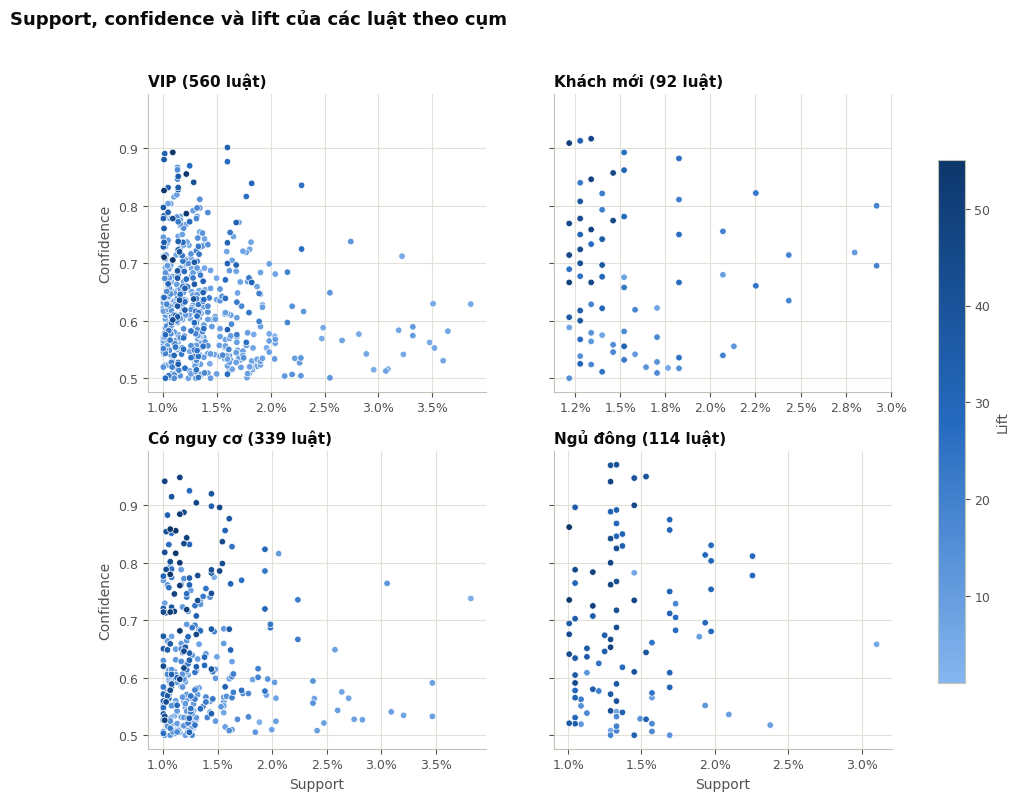

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), sharey=True)
lift_max = rules_all["lift"].quantile(0.99)
for ax, name in zip(axes.ravel(), CLUSTER_ORDER):
    r = rules_all[rules_all["ClusterName"] == name].sort_values("lift")
    points = ax.scatter(r["support"], r["confidence"], c=r["lift"], cmap=LIFT_CMAP, vmin=1, vmax=lift_max,
                        s=22, edgecolor="white", linewidth=0.5)
    ax.set_title(f"{name} ({len(r):,} luật)", fontsize=11)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=1))
    ax.grid(axis="x", visible=True)
for ax in axes[1]:
    ax.set_xlabel("Support")
for ax in axes[:, 0]:
    ax.set_ylabel("Confidence")
fig.colorbar(points, ax=axes, label="Lift", shrink=0.8)
fig.suptitle("Support, confidence và lift của các luật theo cụm", x=0.01, ha="left", fontsize=13, fontweight="bold")
save_fig(fig, "04_luat_theo_cum.png")
plt.show()

**Nhận xét:** - Phần lớn luật có support chỉ từ 1% đến 2% số hóa đơn: mỗi luật áp dụng cho một phần nhỏ hóa đơn, vì cửa hàng có hơn 4.000 sản phẩm và giỏ hàng trải rộng trên nhiều sản phẩm khác nhau.
- Các luật có lift cao nhất (màu đậm) đều nằm ở vùng support thấp, còn các luật có support cao hơn thường nhạt màu. Sản phẩm phổ biến hay xuất hiện cùng nhau, nhưng mức gắn bó không "đặc biệt" bằng các sản phẩm cùng bộ.
- Mọi luật đều có lift từ 3 trở lên, nên điều kiện lọc thực sự quyết định số luật là confidence ≥ 0,5.

## 4. So sánh luật giữa các cụm

### 4.1. Mức độ trùng lặp luật giữa các cụm

Đo bằng **hệ số Jaccard** giữa hai tập luật: số luật chung (cùng vế trái, cùng vế phải) chia cho tổng số luật khác nhau của hai cụm. Jaccard = 1 nghĩa là hai cụm có tập luật giống hệt nhau, = 0 nghĩa là không có luật chung nào.

**Cách đọc:** ô ở hàng A, cột B là hệ số Jaccard giữa cụm A và cụm B (đường chéo luôn bằng 1). Bảng bên dưới biểu đồ cho biết mỗi cụm có bao nhiêu luật, và bao nhiêu luật trong số đó không xuất hiện ở bất kỳ cụm nào khác.

Đã lưu: figures/04_jaccard_luat_giua_cum.png


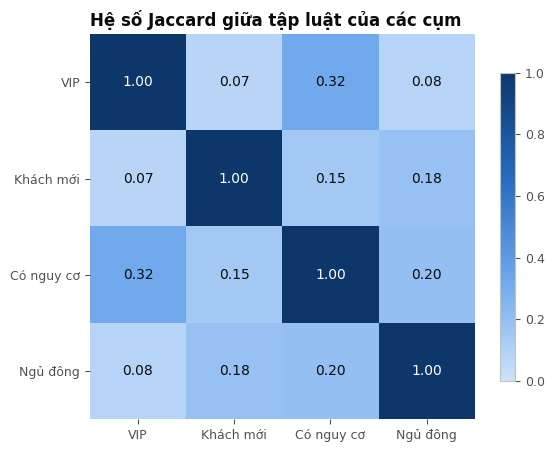

,Số luật,Số luật chỉ có ở cụm này
VIP,560,339
Khách mới,92,33
Có nguy cơ,339,88
Ngủ đông,114,37


In [10]:
rule_keys = {
    name: set(zip(g["Antecedents"], g["Consequents"]))
    for name, g in rules_all.groupby("ClusterName")
}
jaccard = pd.DataFrame(index=CLUSTER_ORDER, columns=CLUSTER_ORDER, dtype=float)
for a in CLUSTER_ORDER:
    for b in CLUSTER_ORDER:
        union = rule_keys[a] | rule_keys[b]
        jaccard.loc[a, b] = len(rule_keys[a] & rule_keys[b]) / len(union) if union else np.nan

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(jaccard.to_numpy(dtype=float), cmap=BLUES, vmin=0, vmax=1)
for i in range(len(CLUSTER_ORDER)):
    for j in range(len(CLUSTER_ORDER)):
        value = jaccard.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=10,
                color="white" if value > 0.5 else INK)
ax.set_xticks(range(4), CLUSTER_ORDER)
ax.set_yticks(range(4), CLUSTER_ORDER)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Hệ số Jaccard giữa tập luật của các cụm")
fig.colorbar(im, ax=ax, shrink=0.8)
save_fig(fig, "04_jaccard_luat_giua_cum.png")
plt.show()

# How many rules of each cluster are unique to that cluster
unique_counts = {
    name: len(rule_keys[name] - set().union(*(rule_keys[o] for o in CLUSTER_ORDER if o != name)))
    for name in CLUSTER_ORDER
}
pd.DataFrame({"Số luật": {n: len(rule_keys[n]) for n in CLUSTER_ORDER},
              "Số luật chỉ có ở cụm này": unique_counts})

### 4.2. Sản phẩm phổ biến và sản phẩm xuất hiện nhiều nhất trong luật của mỗi cụm

Hai bảng dưới đây giúp phân biệt **sản phẩm bán chạy** với **sản phẩm hay được mua kèm**.

**Cách đọc:**

- **Bảng thứ nhất:** 10 sản phẩm có mặt trong nhiều hóa đơn nhất của mỗi cụm. Con số trong ngoặc là tỷ lệ hóa đơn của cụm có sản phẩm đó (support của riêng sản phẩm). Đây cũng là danh sách dùng để bổ sung gợi ý ở mục 5 khi luật kết hợp không đủ.
- **Bảng thứ hai:** 10 sản phẩm xuất hiện (ở vế trái hoặc vế phải) trong nhiều luật nhất của mỗi cụm. Con số trong ngoặc là số luật. Sản phẩm xuất hiện trong nhiều luật là sản phẩm "trung tâm" của các combo.

In [11]:
# Support of single products inside each cluster
product_support = (obs.groupby(["ClusterName", "Description"])["Invoice"].nunique()
                   .div(invoice_counts, level="ClusterName").rename("support").reset_index())

top_products = {}
for name in CLUSTER_ORDER:
    top = (product_support[product_support["ClusterName"] == name]
           .sort_values(["support", "Description"], ascending=[False, True]).head(10))
    top_products[name] = [f"{d} ({s:.1%})" for d, s in zip(top["Description"], top["support"])]
print("Top 10 sản phẩm phổ biến nhất (tỷ lệ hóa đơn có sản phẩm) của từng cụm:")
display(pd.DataFrame(top_products, index=range(1, 11)))

# Products that appear in the most rules (either side) of each cluster
top_rule_items = {}
for name in CLUSTER_ORDER:
    items = rules_all.loc[rules_all["ClusterName"] == name, "Itemset"].explode().value_counts()
    items = items.sort_index().sort_values(ascending=False, kind="stable").head(10)  # ties: by product name
    top_rule_items[name] = [f"{item} ({count})" for item, count in items.items()]
print("Top 10 sản phẩm xuất hiện trong nhiều luật nhất (số luật) của từng cụm:")
display(pd.DataFrame(top_rule_items, index=range(1, 11)))

Top 10 sản phẩm phổ biến nhất (tỷ lệ hóa đơn có sản phẩm) của từng cụm:


,VIP,Khách mới,Có nguy cơ,Ngủ đông
1,WHITE HANGING HEART T-LIGHT HOLDER (14.2%),REGENCY CAKESTAND 3 TIER (8.8%),WHITE HANGING HEART T-LIGHT HOLDER (17.2%),WHITE HANGING HEART T-LIGHT HOLDER (11.7%)
2,JUMBO BAG RED RETROSPOT (10.9%),WHITE HANGING HEART T-LIGHT HOLDER (8.6%),REGENCY CAKESTAND 3 TIER (9.4%),REX CASH+CARRY JUMBO SHOPPER (8.7%)
3,REGENCY CAKESTAND 3 TIER (9.8%),ASSORTED COLOUR BIRD ORNAMENT (8.1%),JUMBO BAG RED RETROSPOT (8.3%),REGENCY CAKESTAND 3 TIER (7.9%)
4,LUNCH BAG RED RETROSPOT (8.9%),BAKING SET 9 PIECE RETROSPOT (6.8%),ASSORTED COLOUR BIRD ORNAMENT (8.1%),ASSORTED COLOUR BIRD ORNAMENT (6.7%)
5,PACK OF 72 RETROSPOT CAKE CASES (7.8%),NATURAL SLATE HEART CHALKBOARD (6.1%),PACK OF 72 RETROSPOT CAKE CASES (7.8%),PACK OF 72 RETROSPOT CAKE CASES (6.2%)
6,ASSORTED COLOUR BIRD ORNAMENT (7.2%),PARTY BUNTING (5.8%),LUNCH BAG RED RETROSPOT (6.7%),NATURAL SLATE HEART CHALKBOARD (5.9%)
7,PARTY BUNTING (6.9%),PACK OF 72 RETROSPOT CAKE CASES (5.6%),HEART OF WICKER LARGE (6.5%),HEART OF WICKER LARGE (5.9%)
8,LUNCH BAG SUKI DESIGN (6.8%),REX CASH+CARRY JUMBO SHOPPER (5.1%),HOME BUILDING BLOCK WORD (6.4%),RETROSPOT TEA SET CERAMIC 11 PC (5.6%)
9,LUNCH BAG BLACK SKULL. (6.4%),JUMBO BAG RED RETROSPOT (5.1%),STRAWBERRY CERAMIC TRINKET BOX (6.4%),BAKING SET 9 PIECE RETROSPOT (5.5%)
10,LUNCH BAG PINK POLKADOT (6.3%),HEART OF WICKER SMALL (4.8%),REX CASH+CARRY JUMBO SHOPPER (6.3%),PAPER CHAIN KIT 50'S CHRISTMAS (5.4%)


Top 10 sản phẩm xuất hiện trong nhiều luật nhất (số luật) của từng cụm:


,VIP,Khách mới,Có nguy cơ,Ngủ đông
1,LUNCH BAG RED RETROSPOT (147),PINK REGENCY TEACUP AND SAUCER (28),LUNCH BAG RED RETROSPOT (39),POPPY'S PLAYHOUSE LIVINGROOM (35)
2,LUNCH BAG SUKI DESIGN (116),GREEN REGENCY TEACUP AND SAUCER (27),LUNCH BAG CARS BLUE (38),POPPY'S PLAYHOUSE KITCHEN (34)
3,LUNCH BAG PINK POLKADOT (107),ROSES REGENCY TEACUP AND SAUCER (27),LUNCH BAG PINK POLKADOT (38),POPPY'S PLAYHOUSE BATHROOM (32)
4,LUNCH BAG SPACEBOY DESIGN (95),REGENCY CAKESTAND 3 TIER (24),LUNCH BAG SUKI DESIGN (37),POPPY'S PLAYHOUSE BEDROOM (32)
5,LUNCH BAG BLACK SKULL. (92),SET OF 12 FAIRY CAKE BAKING CASES (4),LUNCH BAG WOODLAND (37),GREEN REGENCY TEACUP AND SAUCER (9)
6,LUNCH BAG CARS BLUE (91),SET/10 BLUE SPOTTY PARTY CANDLES (4),LUNCH BAG BLACK SKULL. (35),ROSES REGENCY TEACUP AND SAUCER (8)
7,LUNCH BAG WOODLAND (80),SET/10 PINK POLKADOT PARTY CANDLES (4),LUNCH BAG SPACEBOY DESIGN (34),PINK REGENCY TEACUP AND SAUCER (7)
8,JUMBO BAG RED RETROSPOT (74),SET/10 RED POLKADOT PARTY CANDLES (4),60 TEATIME FAIRY CAKE CASES (28),BLUE 3 PIECE MINI DOTS CUTLERY SET (4)
9,JUMBO BAG PINK POLKADOT (55),ALARM CLOCK BAKELIKE PINK (3),PACK OF 72 RETROSPOT CAKE CASES (22),"KEY FOB , SHED (4)"
10,JUMBO STORAGE BAG SUKI (47),ALARM CLOCK BAKELIKE RED (3),GREEN REGENCY TEACUP AND SAUCER (19),PINK 3 PIECE MINI DOTS CUTLERY SET (4)


### 4.3. So sánh trực tiếp VIP và Có nguy cơ

Hai cụm này cùng có lịch sử mua khá, khác nhau chủ yếu ở việc đã lâu chưa quay lại. Ta xem những luật mạnh chỉ có ở cụm này mà không có ở cụm kia. Bảng có cùng các cột và cùng cách đọc như ở mục 3.

In [12]:
def rules_only_in(cluster_a, cluster_b, n=8):
    # Strongest rules of cluster_a that do not exist in cluster_b
    r = rules_all[rules_all["ClusterName"] == cluster_a]
    mask = [key not in rule_keys[cluster_b] for key in zip(r["Antecedents"], r["Consequents"])]
    r = sort_rules(r[mask], by="confidence").drop_duplicates("Itemset")
    return sort_rules(r).head(n)[RULE_COLUMNS].reset_index(drop=True)


fmt = {"support": "{:.3f}", "confidence": "{:.2f}", "lift": "{:.1f}"}
print("Luật mạnh có ở VIP nhưng không có ở Có nguy cơ:")
display(rules_only_in("VIP", "Có nguy cơ").style.format(fmt))
print("Luật mạnh có ở Có nguy cơ nhưng không có ở VIP:")
display(rules_only_in("Có nguy cơ", "VIP").style.format(fmt))

Luật mạnh có ở VIP nhưng không có ở Có nguy cơ:


,Antecedents,Consequents,support,confidence,lift
0,BLUE STRIPE CERAMIC DRAWER KNOB + WHITE SPOT RED CERAMIC DRAWER KNOB,RED STRIPE CERAMIC DRAWER KNOB,0.010,0.88,37.4
1,BLUE SPOT CERAMIC DRAWER KNOB + RED STRIPE CERAMIC DRAWER KNOB,RED SPOT CERAMIC DRAWER KNOB,0.010,0.80,36.8
2,BLUE STRIPE CERAMIC DRAWER KNOB + RED SPOT CERAMIC DRAWER KNOB,RED STRIPE CERAMIC DRAWER KNOB,0.011,0.83,35.3
3,BLUE SPOT CERAMIC DRAWER KNOB + RED STRIPE CERAMIC DRAWER KNOB,BLUE STRIPE CERAMIC DRAWER KNOB,0.010,0.83,33.6
4,BLUE SPOT CERAMIC DRAWER KNOB + RED SPOT CERAMIC DRAWER KNOB,BLUE STRIPE CERAMIC DRAWER KNOB,0.010,0.78,31.6
5,BLUE SPOT CERAMIC DRAWER KNOB,RED SPOT CERAMIC DRAWER KNOB,0.013,0.60,27.5
6,RED STRIPE CERAMIC DRAWER KNOB,BLUE STRIPE CERAMIC DRAWER KNOB,0.016,0.67,27.1
7,RED SPOT CERAMIC DRAWER KNOB,RED STRIPE CERAMIC DRAWER KNOB,0.014,0.64,27.0


Luật mạnh có ở Có nguy cơ nhưng không có ở VIP:


,Antecedents,Consequents,support,confidence,lift
0,CHILDS GARDEN FORK PINK,CHILDS GARDEN TROWEL PINK,0.011,0.86,62.7
1,CHILDS GARDEN TROWEL BLUE,CHILDS GARDEN TROWEL PINK,0.011,0.86,62.5
2,POPPY'S PLAYHOUSE BEDROOM + POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE KITCHEN,0.012,0.95,49.0
3,POPPY'S PLAYHOUSE BATHROOM,POPPY'S PLAYHOUSE KITCHEN,0.010,0.94,48.7
4,SET/6 RED SPOTTY PAPER PLATES,SET/20 RED RETROSPOT PAPER NAPKINS + SET/6 RED SPOTTY PAPER CUPS,0.012,0.62,45.9
5,CHILDS BREAKFAST SET DOLLY GIRL,CHILDS BREAKFAST SET SPACEBOY,0.010,0.71,44.1
6,"KEY FOB , FRONT DOOR","KEY FOB , BACK DOOR",0.011,0.80,43.4
7,COFFEE MUG DOG + BALL DESIGN,COFFEE MUG CAT + BIRD DESIGN,0.013,0.78,43.3


**Nhận xét so sánh giữa các cụm:** - **Mỗi cụm có mẫu mua kèm khá riêng**: hệ số Jaccard giữa các cụm chỉ từ 0,07 đến 0,32. Cặp giống nhau nhất là VIP và Có nguy cơ (0,32), hợp lý vì cả hai đều là khách từng mua nhiều lần, khác nhau chủ yếu ở việc đã lâu chưa quay lại. 339 trên 560 luật của VIP (61%) chỉ xuất hiện ở VIP.
- **Sản phẩm chủ lực thì giống nhau** ở cả 4 cụm (WHITE HANGING HEART T-LIGHT HOLDER, REGENCY CAKESTAND 3 TIER, ASSORTED COLOUR BIRD ORNAMENT, PACK OF 72 RETROSPOT CAKE CASES). Khác biệt giữa các cụm nằm ở **cách mua kèm**, không phải ở sản phẩm bán chạy.
- **VIP**: luật xoay quanh **túi LUNCH BAG nhiều mẫu** (riêng LUNCH BAG RED RETROSPOT có mặt trong 147 luật) và túi JUMBO BAG, cùng các **combo 3 sản phẩm** như núm tủ gốm DRAWER KNOB nhiều màu. VIP nhập hàng theo bộ lớn, mua "sâu" vào từng dòng sản phẩm.
- **Có nguy cơ**: cũng có luật về LUNCH BAG nhưng ít hơn nhiều; các luật riêng của cụm là đồ làm vườn cho trẻ em, POPPY'S PLAYHOUSE, bộ đồ tiệc bằng giấy (khăn ăn, cốc, đĩa), móc khóa KEY FOB, cốc COFFEE MUG theo cặp. Đây là nhóm "quà tặng nhỏ, đồ trẻ em".
- **Khách mới**: luật tập trung vào bộ tách trà REGENCY (xanh, hồng, hoa hồng) đi kèm REGENCY CAKESTAND, và đồ tiệc. Khách mới thường bắt đầu với các sản phẩm "biểu tượng" của cửa hàng.
- **Ngủ đông**: luật chủ yếu là bộ POPPY'S PLAYHOUSE và đồ tiệc; trong top sản phẩm có đồ Giáng sinh (PAPER CHAIN KIT 50'S CHRISTMAS), cho thấy nhiều khách ngủ đông là khách **mua theo mùa lễ**.

## 5. Gợi ý sản phẩm cho khách có nguy cơ rời bỏ cao

### 5.1. Chọn khách có nguy cơ cao

Như đã phân tích ở notebook 03, nếu dùng ngưỡng chung 0,5 thì gần như không có khách VIP nào được chọn (dù 14% VIP thực tế rời bỏ), còn hầu hết khách Ngủ đông bị chọn. Vì vậy ta chọn **25% khách có xác suất churn cao nhất trong từng cụm**. Cách này giúp mỗi cụm đều có danh sách khách cần chăm sóc với quy mô hợp lý, và tận dụng khả năng **xếp hạng** của mô hình bên trong cụm.

In [13]:
threshold = predictions.groupby("ClusterName")["churn_proba"].transform(lambda s: s.quantile(HIGH_RISK_QUANTILE))
predictions["HighRisk"] = predictions["churn_proba"] >= threshold
high_risk = predictions[predictions["HighRisk"]].merge(customers[["CustomerID", "Monetary"]], on="CustomerID")

risk_summary = predictions.groupby("ClusterName").agg(
    NumCustomers=("CustomerID", "size"),
    ProbaThreshold=("churn_proba", lambda s: s.quantile(HIGH_RISK_QUANTILE)),
    ClusterChurnRate=("churn", "mean"),
).reindex(CLUSTER_ORDER)
risk_summary["NumHighRisk"] = high_risk.groupby("ClusterName").size()
risk_summary["HighRiskChurnRate"] = high_risk.groupby("ClusterName")["churn"].mean()
risk_summary["HighRiskMonetary"] = high_risk.groupby("ClusterName")["Monetary"].sum()
risk_summary.rename(columns={
    "NumCustomers": "Số khách", "ProbaThreshold": "Ngưỡng xác suất (phân vị 75%)",
    "ClusterChurnRate": "Tỷ lệ churn cả cụm", "NumHighRisk": "Số khách nguy cơ cao",
    "HighRiskChurnRate": "Tỷ lệ churn thực tế của nhóm được chọn",
    "HighRiskMonetary": "Tổng chi tiêu lịch sử của nhóm được chọn (£)",
}).style.format({
    "Số khách": "{:,}", "Ngưỡng xác suất (phân vị 75%)": "{:.3f}", "Tỷ lệ churn cả cụm": "{:.1%}",
    "Số khách nguy cơ cao": "{:,}", "Tỷ lệ churn thực tế của nhóm được chọn": "{:.1%}",
    "Tổng chi tiêu lịch sử của nhóm được chọn (£)": "{:,.0f}",
})

,Số khách,Ngưỡng xác suất (phân vị 75%),Tỷ lệ churn cả cụm,Số khách nguy cơ cao,Tỷ lệ churn thực tế của nhóm được chọn,Tổng chi tiêu lịch sử của nhóm được chọn (£)
ClusterName,,,,,,
VIP,790,0.191,14.1%,198,28.3%,"939,825"
Khách mới,563,0.473,42.3%,141,56.7%,"82,344"
Có nguy cơ,"1,410",0.591,47.5%,353,66.6%,"479,229"
Ngủ đông,"1,536",0.780,71.4%,384,82.8%,"84,942"


**Cách đọc bảng:**

- `Ngưỡng xác suất (phân vị 75%)`: khách có xác suất churn từ mức này trở lên thuộc nhóm 25% nguy cơ cao nhất của cụm.
- `Tỷ lệ churn cả cụm` và `Tỷ lệ churn thực tế của nhóm được chọn`: tính bằng nhãn thật, dùng để kiểm tra mô hình có chọn đúng những khách thực sự rời bỏ hay không.
- `Tổng chi tiêu lịch sử của nhóm được chọn`: tổng `Monetary` (giai đoạn quan sát) của các khách nguy cơ cao, tức giá trị có nguy cơ bị mất.

**Nhận xét:** - Mỗi cụm chọn 25% khách, tổng cộng **1.076 khách nguy cơ cao**.
- Ngưỡng xác suất của từng cụm rất khác nhau, từ 0,19 (VIP) đến 0,78 (Ngủ đông). Điều này xác nhận dùng một ngưỡng chung cho mọi cụm là không phù hợp.
- Nhóm được chọn có **tỷ lệ churn thực tế cao hơn hẳn** mức chung của cụm: VIP 28,3% (gấp đôi 14,1%), Khách mới 56,7% (so với 42,3%), Có nguy cơ 66,6% (so với 47,5%), Ngủ đông 82,8% (so với 71,4%). Mô hình đã chọn đúng hướng. Vì xác suất của tập train là dự đoán out-of-fold, đánh giá này không bị lạc quan giả tạo.
- **Giá trị cần bảo vệ:** 198 khách VIP nguy cơ cao đã chi tổng cộng **£940K** trong giai đoạn quan sát, nhiều hơn cả nhóm nguy cơ cao của 3 cụm còn lại cộng lại (khoảng £647K). Đây là nhóm cần ưu tiên số một.

### 5.2. Luật mua kèm của toàn cửa hàng (dùng khi luật của cụm không đủ)

Luật của mỗi cụm chỉ được giữ khi xuất hiện trong ít nhất 1% số hóa đơn của cụm. Vì vậy nhiều sản phẩm ít phổ biến hơn không nằm trong luật nào, và những khách chỉ mua các sản phẩm đó (thường là khách mua ít, ở cụm Khách mới và Ngủ đông) không nhận được gợi ý nào từ luật của cụm.

Để vẫn gợi ý được **dựa trên sản phẩm khách đã mua**, ta tìm thêm luật mua kèm trên **toàn bộ hóa đơn** của giai đoạn quan sát (gộp mọi cụm):

- Chỉ xét luật một sản phẩm -> một sản phẩm (A -> B).
- Giữ luật khi có ít nhất 20 hóa đơn chứa cả A và B (`MIN_INVOICES`), confidence ≥ 0,5 và lift > 1. Đây là cùng tiêu chuẩn với luật của cụm, chỉ bỏ điều kiện "ít nhất 1% số hóa đơn".
- Với ngưỡng thấp như vậy (20 trên khoảng 28 nghìn hóa đơn, tức chưa tới 0,1%), FP-Growth phải sinh rất nhiều tập phổ biến (khi thử nghiệm, chạy hơn 10 phút chưa xong). Vì chỉ cần các cặp sản phẩm, ta đếm trực tiếp số hóa đơn chứa từng cặp bằng phép nhân ma trận giỏ hàng (`basket.T @ basket`). Kết quả giống hệt các luật 2 sản phẩm mà FP-Growth tìm được, nhưng chỉ mất vài giây.

Luật của cụm vẫn được **ưu tiên trước**, vì phản ánh đúng hành vi của nhóm khách đó; luật toàn cửa hàng chỉ dùng để lấp các chỗ còn trống.

In [14]:
from scipy import sparse

# Basket matrix of all observation invoices (all clusters): one row per invoice, one column per product
invoice_product = obs[["Invoice", "Description"]].drop_duplicates()
invoice_idx, _ = pd.factorize(invoice_product["Invoice"])
product_idx, product_names = pd.factorize(invoice_product["Description"])
basket_all = sparse.csr_matrix((np.ones(len(invoice_product), dtype=np.int32), (invoice_idx, product_idx)))
n_invoices_all = basket_all.shape[0]
invoice_counts[STORE_SCOPE] = n_invoices_all  # denominator used by explain_rule()

# co_counts[a, b] = number of invoices that contain both product a and product b
co_counts = (basket_all.T @ basket_all).tocoo()
product_counts = np.asarray(basket_all.sum(axis=0)).ravel()

store_rules = pd.DataFrame({"a": co_counts.row, "b": co_counts.col, "both": co_counts.data})
store_rules = store_rules[store_rules["a"] != store_rules["b"]]
store_rules["support"] = store_rules["both"] / n_invoices_all
store_rules["consequent support"] = product_counts[store_rules["b"]] / n_invoices_all
store_rules["confidence"] = store_rules["both"] / product_counts[store_rules["a"]]
store_rules["lift"] = store_rules["confidence"] / store_rules["consequent support"]
store_rules = store_rules[(store_rules["both"] >= MIN_INVOICES) & (store_rules["confidence"] >= MIN_CONFIDENCE)
                          & (store_rules["lift"] > MIN_LIFT)].copy()

# Same columns as rules_all, so the same helper functions can be used
store_rules["Antecedents"] = product_names[store_rules["a"]]
store_rules["Consequents"] = product_names[store_rules["b"]]
store_rules["antecedents"] = [frozenset([p]) for p in store_rules["Antecedents"]]
store_rules["consequents"] = [frozenset([p]) for p in store_rules["Consequents"]]
store_rules["ClusterName"] = STORE_SCOPE
store_rules = sort_rules(store_rules).reset_index(drop=True)

print(f"Luật toàn cửa hàng: {len(store_rules):,} luật, tính trên {n_invoices_all:,} hóa đơn, "
      f"vế trái gồm {store_rules['Antecedents'].nunique():,} sản phẩm khác nhau")
print(f"So sánh: vế trái của luật theo 4 cụm chỉ gồm {rules_all['antecedents'].explode().nunique():,} sản phẩm khác nhau")
display(store_rules.head(10)[RULE_COLUMNS].style.format({"support": "{:.4f}", "confidence": "{:.2f}", "lift": "{:.1f}"}))

Luật toàn cửa hàng: 1,387 luật, tính trên 28,090 hóa đơn, vế trái gồm 839 sản phẩm khác nhau
So sánh: vế trái của luật theo 4 cụm chỉ gồm 186 sản phẩm khác nhau


,Antecedents,Consequents,support,confidence,lift
0,MIRRORED WALL ART GENTS,MIRRORED WALL ART LADIES,0.0008,0.81,847.7
1,MIRRORED WALL ART LADIES,MIRRORED WALL ART GENTS,0.0008,0.81,847.7
2,KITCHEN FLOWER POTS WALL PLAQUE,SMALL KITCHEN FLOWER POTS PLAQUE,0.0007,0.65,671.2
3,SMALL KITCHEN FLOWER POTS PLAQUE,KITCHEN FLOWER POTS WALL PLAQUE,0.0007,0.74,671.2
4,BLUE KNITTED EGG COSY,PINK KNITTED EGG COSY,0.0011,0.86,668.8
5,PINK KNITTED EGG COSY,BLUE KNITTED EGG COSY,0.0011,0.83,668.8
6,SET/6 WOODLAND PAPER PLATES,SET/6 WOODLAND PAPER CUPS,0.0010,0.96,588.8
7,SET/6 WOODLAND PAPER CUPS,SET/6 WOODLAND PAPER PLATES,0.0010,0.59,588.8
8,STAR WREATH DECORATION WITH BELL,HEART WREATH DECORATION WITH BELL,0.0009,0.75,585.2
9,HEART WREATH DECORATION WITH BELL,STAR WREATH DECORATION WITH BELL,0.0009,0.67,585.2


**Cách đọc bảng:** các cột giống bảng ở mục 3, nhưng support, confidence và lift được tính trên toàn bộ hóa đơn của mọi cụm. Support ở đây rất nhỏ (khoảng 0,1%) vì mẫu số là toàn bộ khoảng 28 nghìn hóa đơn.

**Nhận xét:** - Có 1.387 luật toàn cửa hàng. Vế trái của các luật này gồm 839 sản phẩm khác nhau, gấp khoảng 4,5 lần so với 186 sản phẩm ở vế trái của luật theo cụm. Nhờ vậy, nhiều sản phẩm ít phổ biến hơn cũng có căn cứ để gợi ý mua kèm.
- Các luật mạnh nhất vẫn có dạng "cùng bộ, khác mẫu": tranh gương MIRRORED WALL ART nam và nữ, bọc trứng len KNITTED EGG COSY xanh và hồng, đĩa và cốc giấy WOODLAND.
- Lift ở đây rất lớn (trung vị khoảng 92, lớn nhất khoảng 848) vì vế phải thường là sản phẩm ít phổ biến: với một nửa số luật, vế phải chỉ có mặt trong dưới 0,7% số hóa đơn, nên khi confidence đạt 50% đến 80% thì lift lên tới hàng chục, hàng trăm. Khi đọc các luật này, nên chú ý thêm confidence và số hóa đơn làm căn cứ (luôn từ 20 trở lên).

### 5.3. Thuật toán gợi ý

Với mỗi khách có nguy cơ cao, lấy tập sản phẩm khách **đã mua** trong giai đoạn quan sát, rồi điền 5 gợi ý lần lượt từ 3 nguồn:

1. **Luật của cụm** mà khách thuộc về, theo thứ tự lift giảm dần. Nếu **vế trái** của luật nằm trọn trong tập sản phẩm khách đã mua, thì các sản phẩm ở **vế phải** mà khách **chưa mua** được đưa vào danh sách gợi ý.
2. Nếu chưa đủ 5 sản phẩm, dùng tiếp **luật toàn cửa hàng** (mục 5.2) theo đúng cách trên.
3. Nếu vẫn chưa đủ, bổ sung bằng **sản phẩm bán chạy nhất trong cụm** mà khách chưa mua. Đây là gợi ý theo độ phổ biến, **không dựa trên sản phẩm khách đã mua**, nên chỉ dùng khi không còn căn cứ nào khác.

**Lý do gợi ý (cột `Reason`).** Mỗi sản phẩm được gợi ý đều kèm một câu giải thích, để nhân viên bán hàng hoặc người đọc báo cáo hiểu vì sao sản phẩm được chọn:

- **Gợi ý từ luật** (của cụm hoặc của toàn cửa hàng): nêu sản phẩm khách đã mua (vế trái của luật), tỷ lệ hóa đơn có các sản phẩm đó cũng có sản phẩm được gợi ý (confidence), mức tăng so với tỷ lệ chung (lift) và số hóa đơn làm căn cứ.
- **Gợi ý từ hàng bán chạy:** nêu cụ thể khách đã mua những gì và **vì sao** luật không cho đủ 5 gợi ý. Có đúng 3 trường hợp, được code xác định cho từng khách: không luật nào có vế trái nằm trọn trong các sản phẩm khách đã mua; có luật khớp nhưng các luật đó chỉ gợi ý sản phẩm khách đã có; hoặc luật chỉ cho được vài gợi ý. Sau đó nêu thứ hạng và độ phổ biến của sản phẩm trong cụm.

**Các cột của bảng gợi ý:**

| Cột | Ý nghĩa |
|---|---|
| `Rank` | Thứ tự ưu tiên trong 5 gợi ý của khách (1 là nên giới thiệu trước) |
| `RecommendedProduct` | Sản phẩm được gợi ý |
| `Source` | Nguồn gợi ý: `Luật của cụm`, `Luật toàn cửa hàng` hoặc `Bán chạy trong cụm` |
| `BasedOn` | Sản phẩm khách đã mua làm căn cứ (vế trái của luật); để trống nếu là hàng bán chạy |
| `Confidence`, `Lift` | Chỉ số của luật được dùng; để trống nếu là hàng bán chạy |
| `Reason` | Lý do gợi ý, viết bằng lời |

In [15]:
customer_items = obs.groupby("CustomerID")["Description"].agg(set)

# Best sellers of each cluster as (product, support), ties by name; used as a fallback
popular_items = {
    name: list(product_support[product_support["ClusterName"] == name]
               .sort_values(["support", "Description"], ascending=[False, True])
               .head(100)[["Description", "support"]].itertuples(index=False, name=None))
    for name in CLUSTER_ORDER
}

# Rules as lists of dicts, strongest first (lift, then confidence, then names)
rules_lookup = {name: sort_rules(g).to_dict("records") for name, g in rules_all.groupby("ClusterName")}
store_lookup = store_rules.to_dict("records")

SOURCE_CLUSTER = "Luật của cụm"
SOURCE_STORE = "Luật toàn cửa hàng"
SOURCE_POPULAR = "Bán chạy trong cụm"
SOURCES = [SOURCE_CLUSTER, SOURCE_STORE, SOURCE_POPULAR]


def rule_recs(rules, bought, chosen, source, slots):
    # Right-hand-side products of the rules whose left-hand side the customer has fully bought.
    # Also returns how many rules matched, to explain the fallback when they give nothing new.
    recs, n_matched = [], 0
    for rule in rules:
        if len(recs) >= slots:
            break
        if rule["antecedents"] <= bought:
            n_matched += 1
            for item in sorted(rule["consequents"]):  # sets have no fixed order
                if item not in bought and item not in chosen:
                    chosen.add(item)
                    recs.append({"RecommendedProduct": item, "Source": source,
                                 "BasedOn": " + ".join(sorted(rule["antecedents"])),
                                 "Confidence": rule["confidence"], "Lift": rule["lift"],
                                 "Reason": f"Khách đã mua {join_names(rule['antecedents'])}. {explain_rule(rule)}"})
    return recs[:slots], n_matched


def fallback_reason(bought, n_from_rules, n_matched_rules):
    # Exactly why the rules could not fill the list, stated with the customer's own purchases
    if len(bought) <= 5:
        what = f"Khách chỉ mua {len(bought)} sản phẩm ({join_names(bought)})"
    else:
        what = f"Khách đã mua {len(bought)} sản phẩm khác nhau"
    if n_from_rules > 0:
        return f"{what}; các luật mua kèm chỉ cho {n_from_rules} gợi ý, chưa đủ {TOP_N}."
    if n_matched_rules == 0:
        return (f"{what}, nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) "
                f"có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua.")
    return (f"{what}; có {n_matched_rules} luật khớp với các sản phẩm này, "
            f"nhưng các luật đó chỉ gợi ý những sản phẩm khách đã mua rồi.")


def recommend(customer_id, cluster_name, top_n=TOP_N):
    bought = customer_items[customer_id]
    chosen = set()
    # 1) Rules of the customer's own cluster, then 2) store-wide rules for the remaining slots
    recs, n_matched_cluster = rule_recs(rules_lookup.get(cluster_name, []), bought, chosen, SOURCE_CLUSTER, top_n)
    store_part, n_matched_store = rule_recs(store_lookup, bought, chosen, SOURCE_STORE, top_n - len(recs))
    recs += store_part

    # 3) Fallback: best sellers of the cluster the customer has not bought yet
    if len(recs) < top_n:
        why = fallback_reason(bought, len(recs), n_matched_cluster + n_matched_store)
        for rank, (item, support) in enumerate(popular_items[cluster_name], start=1):
            if len(recs) >= top_n:
                break
            if item not in bought and item not in chosen:
                chosen.add(item)
                recs.append({"RecommendedProduct": item, "Source": SOURCE_POPULAR, "BasedOn": "",
                             "Confidence": np.nan, "Lift": np.nan,
                             "Reason": (f"{why} Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ {rank} "
                                        f"của cụm {cluster_name} (có trong {pct(support)} hóa đơn của cụm) mà khách chưa mua. "
                                        f"Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua.")})
    return recs

In [16]:
rows = []
for customer in high_risk.itertuples(index=False):
    for rank, rec in enumerate(recommend(customer.CustomerID, customer.ClusterName), start=1):
        rows.append({"CustomerID": customer.CustomerID, "ClusterName": customer.ClusterName,
                     "churn_proba": customer.churn_proba, "Rank": rank, **rec})
recommendations = pd.DataFrame(rows)

# Coverage: how many high-risk customers get recommendations based on what they bought
rule_based = recommendations[recommendations["Source"] == SOURCE_CLUSTER]
any_rule = recommendations[recommendations["Source"].isin([SOURCE_CLUSTER, SOURCE_STORE])]
n_high_risk = high_risk.groupby("ClusterName").size()
coverage = pd.DataFrame({
    "Số khách nguy cơ cao": n_high_risk,
    "Có gợi ý từ luật của cụm": rule_based.groupby("ClusterName")["CustomerID"].nunique(),
    "Có gợi ý từ luật (cụm hoặc toàn cửa hàng)": any_rule.groupby("ClusterName")["CustomerID"].nunique(),
}).reindex(CLUSTER_ORDER).fillna(0).astype(int)
coverage["Chỉ nhận hàng bán chạy"] = coverage["Số khách nguy cơ cao"] - coverage["Có gợi ý từ luật (cụm hoặc toàn cửa hàng)"]
for col in ["Có gợi ý từ luật của cụm", "Có gợi ý từ luật (cụm hoặc toàn cửa hàng)", "Chỉ nhận hàng bán chạy"]:
    coverage[f"% {col.lower()}"] = coverage[col] / coverage["Số khách nguy cơ cao"]
print(f"Tổng số dòng gợi ý: {len(recommendations):,} cho {recommendations['CustomerID'].nunique():,} khách")
display(coverage.style.format({c: "{:.1%}" for c in coverage.columns if c.startswith("%")}))

# Number of recommendation slots (out of 5 per customer) filled by each source
slots_by_source = (recommendations.groupby(["ClusterName", "Source"]).size().unstack(fill_value=0)
                   .reindex(index=CLUSTER_ORDER, columns=SOURCES, fill_value=0))
print("Số gợi ý theo nguồn:")
slots_by_source

Tổng số dòng gợi ý: 5,380 cho 1,076 khách


,Số khách nguy cơ cao,Có gợi ý từ luật của cụm,Có gợi ý từ luật (cụm hoặc toàn cửa hàng),Chỉ nhận hàng bán chạy,% có gợi ý từ luật của cụm,% có gợi ý từ luật (cụm hoặc toàn cửa hàng),% chỉ nhận hàng bán chạy
ClusterName,,,,,,,
VIP,198,171,191,7,86.4%,96.5%,3.5%
Khách mới,141,45,102,39,31.9%,72.3%,27.7%
Có nguy cơ,353,266,321,32,75.4%,90.9%,9.1%
Ngủ đông,384,89,244,140,23.2%,63.5%,36.5%


Số gợi ý theo nguồn:


Source,Luật của cụm,Luật toàn cửa hàng,Bán chạy trong cụm
ClusterName,,,
VIP,627,232,131
Khách mới,75,261,369
Có nguy cơ,830,487,448
Ngủ đông,137,497,1286


**Cách đọc bảng thứ nhất** (số khách):

- `Có gợi ý từ luật của cụm`: số khách nhận được ít nhất 1 gợi ý từ luật của cụm mình.
- `Có gợi ý từ luật (cụm hoặc toàn cửa hàng)`: số khách nhận được ít nhất 1 gợi ý dựa trên sản phẩm đã mua, từ bất kỳ loại luật nào.
- `Chỉ nhận hàng bán chạy`: số khách không có căn cứ mua kèm nào, nên cả 5 gợi ý đều là hàng bán chạy của cụm.
- Ba cột cuối là các tỷ lệ tương ứng, tính trên số khách nguy cơ cao của cụm.

**Bảng thứ hai** cho biết trong tổng số gợi ý của mỗi cụm (5 gợi ý × số khách), bao nhiêu gợi ý đến từ mỗi nguồn.

**Nhận xét:** - **Luật của cụm đủ cho phần lớn khách VIP (86,4%) và Có nguy cơ (75,4%)**, vì những khách này đã mua nhiều loại sản phẩm nên dễ khớp với vế trái của luật. Ngược lại, chỉ 31,9% khách Khách mới và 23,2% khách Ngủ đông nhận được gợi ý từ luật của cụm: họ mua ít loại sản phẩm, và cụm của họ cũng có ít luật.
- **Luật toàn cửa hàng lấp được phần lớn khoảng trống.** Nếu chỉ dùng luật của cụm, 505 trên 1.076 khách (47%) không có gợi ý nào dựa trên sản phẩm đã mua; khi thêm luật toàn cửa hàng, con số này giảm còn 218 khách (20%). Tỷ lệ khách có gợi ý theo sản phẩm đã mua tăng lên 96,5% ở VIP, 72,3% ở Khách mới, 90,9% ở Có nguy cơ và 63,5% ở Ngủ đông.
- 218 khách còn lại phần lớn thuộc cụm Ngủ đông (140 khách) và mua rất ít: trung vị chỉ 4 sản phẩm. Với 139 khách, không có luật nào có vế trái khớp với sản phẩm họ đã mua; với 79 khách còn lại, các luật khớp chỉ gợi ý những sản phẩm họ đã có. Những khách này chỉ có thể nhận gợi ý theo độ phổ biến. Đây là giới hạn tự nhiên của phương pháp luật kết hợp với khách có ít lịch sử mua (tương tự vấn đề *cold start* trong hệ gợi ý).

### 5.4. Minh họa với một số khách cụ thể

Với mỗi cụm, chọn khách nguy cơ cao có **tổng chi tiêu lớn nhất** (khách giá trị nhất cần giữ), ưu tiên những khách nhận được từ 3 gợi ý dựa trên luật của cụm trở lên để minh họa rõ cách luật hoạt động.

**Cách đọc:** dòng tiêu đề tóm tắt hồ sơ của khách (xác suất churn, số ngày chưa mua, số hóa đơn, tổng chi tiêu, số sản phẩm đã mua). Bảng bên dưới là 5 gợi ý theo thứ tự ưu tiên, cột `Reason` giải thích lý do của từng gợi ý.

In [17]:
num_rule_recs = rule_based.groupby("CustomerID").size().clip(upper=3).rename("NumRuleRecs")
example_ids = (
    high_risk.join(num_rule_recs, on="CustomerID")
    .fillna({"NumRuleRecs": 0})
    .sort_values(["NumRuleRecs", "Monetary", "CustomerID"], ascending=[False, False, True])
    .drop_duplicates("ClusterName")
    .set_index("ClusterName")
    .reindex(CLUSTER_ORDER)["CustomerID"]
    .dropna().astype(int)
)

def show_customer(customer_id):
    # Profile line + the 5 recommendations of one customer, with their reasons
    info = customers.set_index("CustomerID").loc[customer_id]
    proba = predictions.set_index("CustomerID").loc[customer_id, "churn_proba"]
    print(f"\n=== Khách {customer_id} | cụm {info['ClusterName']} | xác suất churn {proba:.2f} | "
          f"Recency {info['Recency']} ngày, {info['Frequency']} hóa đơn, chi £{info['Monetary']:,.0f}, "
          f"đã mua {len(customer_items[customer_id])} sản phẩm khác nhau ===")
    display(recommendations[recommendations["CustomerID"] == customer_id]
            [["Rank", "RecommendedProduct", "Source", "Reason"]]
            .style.hide(axis="index").set_properties(subset=["Reason"], **{"text-align": "left"}))


for customer_id in example_ids:
    show_customer(customer_id)


=== Khách 13093 | cụm VIP | xác suất churn 0.21 | Recency 185 ngày, 55 hóa đơn, chi £53,869, đã mua 198 sản phẩm khác nhau ===


Rank,RecommendedProduct,Source,Reason
1,HAND WARMER OWL DESIGN,Luật của cụm,"Khách đã mua HAND WARMER BIRD DESIGN. Trong cụm VIP, 57,5% hóa đơn có HAND WARMER BIRD DESIGN cũng có HAND WARMER OWL DESIGN, cao gấp 28,1 lần tỷ lệ chung của cụm (2,0%). Có 164 hóa đơn chứa đồng thời các sản phẩm này."
2,EDWARDIAN PARASOL NATURAL,Luật của cụm,"Khách đã mua EDWARDIAN PARASOL BLACK. Trong cụm VIP, 54,0% hóa đơn có EDWARDIAN PARASOL BLACK cũng có EDWARDIAN PARASOL NATURAL, cao gấp 17,3 lần tỷ lệ chung của cụm (3,1%). Có 249 hóa đơn chứa đồng thời các sản phẩm này."
3,ROUND SNACK BOXES SET OF4 WOODLAND,Luật của cụm,"Khách đã mua ROUND SNACK BOXES SET OF 4 FRUITS. Trong cụm VIP, 53,5% hóa đơn có ROUND SNACK BOXES SET OF 4 FRUITS cũng có ROUND SNACK BOXES SET OF4 WOODLAND, cao gấp 15,1 lần tỷ lệ chung của cụm (3,5%). Có 280 hóa đơn chứa đồng thời các sản phẩm này."
4,JUMBO BAG SCANDINAVIAN PAISLEY,Luật của cụm,"Khách đã mua JUMBO BAG PINK VINTAGE PAISLEY và JUMBO BAG STRAWBERRY. Trong cụm VIP, 62,6% hóa đơn có đủ JUMBO BAG PINK VINTAGE PAISLEY và JUMBO BAG STRAWBERRY cũng có JUMBO BAG SCANDINAVIAN PAISLEY, cao gấp 14,8 lần tỷ lệ chung của cụm (4,2%). Có 169 hóa đơn chứa đồng thời các sản phẩm này."
5,LUNCH BAG PINK POLKADOT,Luật của cụm,"Khách đã mua LUNCH BAG CARS BLUE, LUNCH BAG RED RETROSPOT và LUNCH BAG SPACEBOY DESIGN. Trong cụm VIP, 69,6% hóa đơn có đủ LUNCH BAG CARS BLUE, LUNCH BAG RED RETROSPOT và LUNCH BAG SPACEBOY DESIGN cũng có LUNCH BAG PINK POLKADOT, cao gấp 11,1 lần tỷ lệ chung của cụm (6,3%). Có 167 hóa đơn chứa đồng thời các sản phẩm này."



=== Khách 12670 | cụm Khách mới | xác suất churn 0.48 | Recency 8 ngày, 5 hóa đơn, chi £2,183, đã mua 53 sản phẩm khác nhau ===


Rank,RecommendedProduct,Source,Reason
1,ROUND SNACK BOXES SET OF4 WOODLAND,Luật của cụm,"Khách đã mua ROUND SNACK BOXES SET OF 4 FRUITS. Trong cụm Khách mới, 62,9% hóa đơn có ROUND SNACK BOXES SET OF 4 FRUITS cũng có ROUND SNACK BOXES SET OF4 WOODLAND, cao gấp 19,1 lần tỷ lệ chung của cụm (3,3%). Có 22 hóa đơn chứa đồng thời các sản phẩm này."
2,DOLLY GIRL LUNCH BOX,Luật của cụm,"Khách đã mua SPACEBOY LUNCH BOX. Trong cụm Khách mới, 69,6% hóa đơn có SPACEBOY LUNCH BOX cũng có DOLLY GIRL LUNCH BOX, cao gấp 19,0 lần tỷ lệ chung của cụm (3,7%). Có 48 hóa đơn chứa đồng thời các sản phẩm này."
3,PLASTERS IN TIN WOODLAND ANIMALS,Luật của cụm,"Khách đã mua PLASTERS IN TIN CIRCUS PARADE. Trong cụm Khách mới, 58,1% hóa đơn có PLASTERS IN TIN CIRCUS PARADE cũng có PLASTERS IN TIN WOODLAND ANIMALS, cao gấp 16,5 lần tỷ lệ chung của cụm (3,5%). Có 25 hóa đơn chứa đồng thời các sản phẩm này."
4,QUEENS GUARD COFFEE MUG,Luật toàn cửa hàng,"Khách đã mua LONDON BUS COFFEE MUG. Trên toàn cửa hàng (mọi cụm), 52,4% hóa đơn có LONDON BUS COFFEE MUG cũng có QUEENS GUARD COFFEE MUG, cao gấp 90,3 lần tỷ lệ chung của cửa hàng (0,6%). Có 98 hóa đơn chứa đồng thời các sản phẩm này."
5,COFFEE MUG PEARS DESIGN,Luật toàn cửa hàng,"Khách đã mua COFFEE MUG APPLES DESIGN. Trên toàn cửa hàng (mọi cụm), 52,6% hóa đơn có COFFEE MUG APPLES DESIGN cũng có COFFEE MUG PEARS DESIGN, cao gấp 53,6 lần tỷ lệ chung của cửa hàng (1,0%). Có 210 hóa đơn chứa đồng thời các sản phẩm này."



=== Khách 15523 | cụm Có nguy cơ | xác suất churn 0.59 | Recency 298 ngày, 15 hóa đơn, chi £16,847, đã mua 63 sản phẩm khác nhau ===


Rank,RecommendedProduct,Source,Reason
1,SET/10 BLUE SPOTTY PARTY CANDLES,Luật của cụm,"Khách đã mua SET/10 PINK POLKADOT PARTY CANDLES. Trong cụm Có nguy cơ, 64,8% hóa đơn có SET/10 PINK POLKADOT PARTY CANDLES cũng có SET/10 BLUE SPOTTY PARTY CANDLES, cao gấp 30,5 lần tỷ lệ chung của cụm (2,1%). Có 129 hóa đơn chứa đồng thời các sản phẩm này."
2,BLUE HAPPY BIRTHDAY BUNTING,Luật của cụm,"Khách đã mua PINK HAPPY BIRTHDAY BUNTING. Trong cụm Có nguy cơ, 57,8% hóa đơn có PINK HAPPY BIRTHDAY BUNTING cũng có BLUE HAPPY BIRTHDAY BUNTING, cao gấp 25,9 lần tỷ lệ chung của cụm (2,2%). Có 137 hóa đơn chứa đồng thời các sản phẩm này."
3,SET/10 RED POLKADOT PARTY CANDLES,Luật của cụm,"Khách đã mua SET/10 PINK POLKADOT PARTY CANDLES. Trong cụm Có nguy cơ, 55,8% hóa đơn có SET/10 PINK POLKADOT PARTY CANDLES cũng có SET/10 RED POLKADOT PARTY CANDLES, cao gấp 22,3 lần tỷ lệ chung của cụm (2,5%). Có 111 hóa đơn chứa đồng thời các sản phẩm này."
4,MILK PAN RED RETROSPOT,Luật toàn cửa hàng,"Khách đã mua FRYING PAN RED POLKADOT. Trên toàn cửa hàng (mọi cụm), 54,8% hóa đơn có FRYING PAN RED POLKADOT cũng có MILK PAN RED RETROSPOT, cao gấp 71,3 lần tỷ lệ chung của cửa hàng (0,8%). Có 120 hóa đơn chứa đồng thời các sản phẩm này."
5,PACK OF 6 SKULL PAPER PLATES,Luật toàn cửa hàng,"Khách đã mua PACK OF 20 SKULL PAPER NAPKINS. Trên toàn cửa hàng (mọi cụm), 53,5% hóa đơn có PACK OF 20 SKULL PAPER NAPKINS cũng có PACK OF 6 SKULL PAPER PLATES, cao gấp 52,1 lần tỷ lệ chung của cửa hàng (1,0%). Có 209 hóa đơn chứa đồng thời các sản phẩm này."



=== Khách 12874 | cụm Ngủ đông | xác suất churn 0.80 | Recency 295 ngày, 2 hóa đơn, chi £858, đã mua 42 sản phẩm khác nhau ===


Rank,RecommendedProduct,Source,Reason
1,PACK OF 60 DINOSAUR CAKE CASES,Luật của cụm,"Khách đã mua PACK OF 60 SPACEBOY CAKE CASES. Trong cụm Ngủ đông, 57,7% hóa đơn có PACK OF 60 SPACEBOY CAKE CASES cũng có PACK OF 60 DINOSAUR CAKE CASES, cao gấp 20,8 lần tỷ lệ chung của cụm (2,8%). Có 30 hóa đơn chứa đồng thời các sản phẩm này."
2,VINTAGE SNAP CARDS,Luật của cụm,"Khách đã mua VINTAGE HEADS AND TAILS CARD GAME. Trong cụm Ngủ đông, 55,2% hóa đơn có VINTAGE HEADS AND TAILS CARD GAME cũng có VINTAGE SNAP CARDS, cao gấp 12,7 lần tỷ lệ chung của cụm (4,4%). Có 48 hóa đơn chứa đồng thời các sản phẩm này."
3,PACK OF 60 PINK PAISLEY CAKE CASES,Luật của cụm,"Khách đã mua PACK OF 60 MUSHROOM CAKE CASES. Trong cụm Ngủ đông, 57,8% hóa đơn có PACK OF 60 MUSHROOM CAKE CASES cũng có PACK OF 60 PINK PAISLEY CAKE CASES, cao gấp 12,6 lần tỷ lệ chung của cụm (4,6%). Có 26 hóa đơn chứa đồng thời các sản phẩm này."
4,PACK OF 72 RETROSPOT CAKE CASES,Luật của cụm,"Khách đã mua PACK OF 60 SPACEBOY CAKE CASES. Trong cụm Ngủ đông, 57,7% hóa đơn có PACK OF 60 SPACEBOY CAKE CASES cũng có PACK OF 72 RETROSPOT CAKE CASES, cao gấp 9,4 lần tỷ lệ chung của cụm (6,2%). Có 30 hóa đơn chứa đồng thời các sản phẩm này."
5,SILK PURSE BABUSHKA BLUE,Luật toàn cửa hàng,"Khách đã mua SILK PURSE BABUSHKA RED. Trên toàn cửa hàng (mọi cụm), 57,0% hóa đơn có SILK PURSE BABUSHKA RED cũng có SILK PURSE BABUSHKA BLUE, cao gấp 107,4 lần tỷ lệ chung của cửa hàng (0,5%). Có 110 hóa đơn chứa đồng thời các sản phẩm này."


Ngoài ra, xem khách có **xác suất churn cao nhất** trong toàn bộ danh sách. Khách này mua rất ít, nên minh họa cách các nguồn gợi ý dự phòng (luật toàn cửa hàng, hàng bán chạy) được dùng và được giải thích.

In [18]:
top_risk_customer = high_risk.sort_values(["churn_proba", "CustomerID"], ascending=[False, True])["CustomerID"].iloc[0]
show_customer(top_risk_customer)


=== Khách 13254 | cụm Ngủ đông | xác suất churn 0.93 | Recency 286 ngày, 1 hóa đơn, chi £51, đã mua 4 sản phẩm khác nhau ===


Rank,RecommendedProduct,Source,Reason
1,STRAWBRY SCENTED VOTIVE CANDLE,Luật toàn cửa hàng,"Khách đã mua ORANGE VOTIVE CANDLE. Trên toàn cửa hàng (mọi cụm), 77,8% hóa đơn có ORANGE VOTIVE CANDLE cũng có STRAWBRY SCENTED VOTIVE CANDLE, cao gấp 370,3 lần tỷ lệ chung của cửa hàng (0,2%). Có 28 hóa đơn chứa đồng thời các sản phẩm này."
2,CINNAMON SCENTED VOTIVE CANDLE,Luật toàn cửa hàng,"Khách đã mua ORANGE VOTIVE CANDLE. Trên toàn cửa hàng (mọi cụm), 55,6% hóa đơn có ORANGE VOTIVE CANDLE cũng có CINNAMON SCENTED VOTIVE CANDLE, cao gấp 346,8 lần tỷ lệ chung của cửa hàng (0,2%). Có 20 hóa đơn chứa đồng thời các sản phẩm này."
3,WHITE HANGING HEART T-LIGHT HOLDER,Bán chạy trong cụm,"Khách chỉ mua 4 sản phẩm (FRENCH LAVENDER SCENT HEART, LAVENDER SCENTED FABRIC HEART, ORANGE VOTIVE CANDLE và WOOD BLACK BOARD ANT WHITE FINISH); các luật mua kèm chỉ cho 2 gợi ý, chưa đủ 5. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 1 của cụm Ngủ đông (có trong 11,7% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
4,REX CASH+CARRY JUMBO SHOPPER,Bán chạy trong cụm,"Khách chỉ mua 4 sản phẩm (FRENCH LAVENDER SCENT HEART, LAVENDER SCENTED FABRIC HEART, ORANGE VOTIVE CANDLE và WOOD BLACK BOARD ANT WHITE FINISH); các luật mua kèm chỉ cho 2 gợi ý, chưa đủ 5. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 2 của cụm Ngủ đông (có trong 8,7% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
5,REGENCY CAKESTAND 3 TIER,Bán chạy trong cụm,"Khách chỉ mua 4 sản phẩm (FRENCH LAVENDER SCENT HEART, LAVENDER SCENTED FABRIC HEART, ORANGE VOTIVE CANDLE và WOOD BLACK BOARD ANT WHITE FINISH); các luật mua kèm chỉ cho 2 gợi ý, chưa đủ 5. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 3 của cụm Ngủ đông (có trong 7,9% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."


**Nhận xét:** Khách 13254 có xác suất churn cao nhất (0,93): chỉ có 1 hóa đơn trị giá £51 với 4 sản phẩm, mua lần cuối cách đây 286 ngày. Không sản phẩm nào của khách nằm trong luật của cụm Ngủ đông, nhưng luật toàn cửa hàng cho thấy khách mua nến ORANGE VOTIVE CANDLE thường mua cả nến mùi khác (STRAWBERRY, CINNAMON), nên 2 gợi ý đầu là các loại nến này. Ba gợi ý còn lại là hàng bán chạy của cụm; cột `Reason` liệt kê đúng 4 sản phẩm khách đã mua, nói rõ luật chỉ cho được 2 gợi ý, và ghi rõ đây là gợi ý theo độ phổ biến.

**Nhận xét:** - **Khách VIP 13093**: 55 hóa đơn, đã chi £53.869, nhưng đã 185 ngày không đặt hàng (xác suất churn 0,21, thấp so với các cụm khác nhưng thuộc 25% cao nhất của VIP). Cả 5 gợi ý đều đến từ luật kết hợp và đều mang tính **"bổ sung mẫu còn thiếu"**: túi giữ ấm HAND WARMER mẫu cú khi khách đã có mẫu chim, ô EDWARDIAN PARASOL màu tự nhiên khi đã có màu đen, túi LUNCH BAG PINK POLKADOT khi khách đã nhập 3 mẫu lunch bag khác. Đây là nội dung phù hợp cho một cuộc gọi hoặc email chăm sóc cá nhân.
- **Khách mới 12670**: vừa mua 8 ngày trước nhưng xác suất churn vẫn 0,48. Gợi ý hộp snack mẫu WOODLAND (đã mua mẫu FRUITS), hộp cơm DOLLY GIRL LUNCH BOX (đã mua mẫu SPACEBOY)... giúp tăng giá trị đơn hàng thứ 6 và tạo lý do quay lại. Luật của cụm chỉ cho 3 gợi ý; 2 gợi ý còn lại đến từ luật toàn cửa hàng: khách đã mua cốc LONDON BUS COFFEE MUG và COFFEE MUG APPLES DESIGN, nên được gợi ý các mẫu cốc cùng dòng (QUEENS GUARD, PEARS).
- **Khách Có nguy cơ 15523**: từng mua 15 lần với £16.847 nhưng đã 298 ngày chưa quay lại. Khách đã mua nến tiệc màu hồng và dây cờ HAPPY BIRTHDAY BUNTING màu hồng, nên được gợi ý các màu còn thiếu (nến xanh, nến đỏ, dây cờ xanh). Hai gợi ý cuối đến từ luật toàn cửa hàng: nồi MILK PAN RED RETROSPOT đi kèm chảo FRYING PAN RED POLKADOT, và đĩa giấy SKULL đi kèm khăn giấy SKULL mà khách đã mua.
- **Khách Ngủ đông 12874** (2 hóa đơn, 295 ngày chưa quay lại): gợi ý các mẫu giấy lót bánh CAKE CASES khác (DINOSAUR, PINK PAISLEY, RETROSPOT) cùng bộ với mẫu SPACEBOY, MUSHROOM khách từng mua, và bộ bài VINTAGE SNAP CARDS đi kèm VINTAGE HEADS AND TAILS CARD GAME. Gợi ý thứ 5 lấy từ luật toàn cửa hàng: ví lụa SILK PURSE BABUSHKA màu xanh, vì khách đã mua màu đỏ.
- Cột `Reason` cho biết **vì sao** từng sản phẩm được gợi ý: dựa trên sản phẩm nào khách đã mua, luật đó là luật của cụm hay của toàn cửa hàng, mạnh đến đâu và có bao nhiêu hóa đơn làm căn cứ. Nhờ vậy nhân viên bán hàng dễ giải thích và tin tưởng gợi ý, điều mà các phương pháp "hộp đen" khó làm được.

### 5.5. Kiểm tra nhanh chất lượng gợi ý trên giai đoạn dự đoán

Luật kết hợp và danh sách gợi ý được xây dựng **chỉ từ giai đoạn quan sát**. Ta có thể dùng giai đoạn dự đoán (10/09 đến 09/12/2011), lúc này chỉ với vai trò **đánh giá**, để kiểm tra: những khách nguy cơ cao **đã quay lại mua** có tự mua đúng sản phẩm được gợi ý hay không?

- Một gợi ý được tính là **trúng** nếu khách mua sản phẩm đó trong giai đoạn dự đoán.
- Chỉ xét khách đã quay lại, vì khách không quay lại thì không thể mua bất kỳ sản phẩm nào.
- Đây là hành vi mua **tự nhiên** (khách chưa hề nhận được gợi ý nào), nên tỷ lệ trúng chỉ phản ánh mức độ gợi ý **khớp với nhu cầu thật** của khách; hiệu quả thực của một chiến dịch cần được đo bằng thử nghiệm A/B.

In [19]:
# Evaluation only: the prediction period was NOT used to build the rules or the recommendations
pred_period = transactions[transactions["InvoiceDate"] >= REF_DATE]
bought_later = set(zip(pred_period["CustomerID"], pred_period["Description"]))
returned_customers = set(pred_period["CustomerID"])

evaluation = recommendations[recommendations["CustomerID"].isin(returned_customers)].copy()
evaluation["Hit"] = [(c, p) in bought_later for c, p in zip(evaluation["CustomerID"], evaluation["RecommendedProduct"])]
print(f"Khách nguy cơ cao đã quay lại mua: {evaluation['CustomerID'].nunique():,} / {high_risk['CustomerID'].nunique():,}")

hit_rows = []
for name in CLUSTER_ORDER + ["Tất cả"]:
    part = evaluation if name == "Tất cả" else evaluation[evaluation["ClusterName"] == name]
    row = {"Cụm": name}
    for source in SOURCES:
        hits = part.loc[part["Source"] == source, "Hit"]
        row[f"Tỷ lệ trúng ({source})"] = hits.mean()
        row[f"Số gợi ý ({source})"] = len(hits)
    hit_rows.append(row)
hit_summary = pd.DataFrame(hit_rows).set_index("Cụm")
hit_summary.style.format({col: "{:.1%}" if col.startswith("Tỷ lệ") else "{:,}" for col in hit_summary.columns},
                         na_rep="")

Khách nguy cơ cao đã quay lại mua: 387 / 1,076


,Tỷ lệ trúng (Luật của cụm),Số gợi ý (Luật của cụm),Tỷ lệ trúng (Luật toàn cửa hàng),Số gợi ý (Luật toàn cửa hàng),Tỷ lệ trúng (Bán chạy trong cụm),Số gợi ý (Bán chạy trong cụm)
Cụm,,,,,,
VIP,4.8%,457,3.8%,159,1.1%,94
Khách mới,15.0%,40,11.5%,122,2.1%,143
Có nguy cơ,8.3%,300,4.7%,169,3.3%,121
Ngủ đông,3.3%,30,4.6%,108,5.7%,192
Tất cả,6.5%,827,5.9%,558,3.5%,550


**Cách đọc bảng:** chỉ tính trên các khách nguy cơ cao đã quay lại mua.

- `Tỷ lệ trúng (nguồn)`: trong các gợi ý đến từ nguồn đó, tỷ lệ sản phẩm mà khách thực sự mua trong giai đoạn dự đoán.
- `Số gợi ý (nguồn)`: số gợi ý từ nguồn đó được dùng để tính tỷ lệ. Số này càng nhỏ thì tỷ lệ càng kém tin cậy.
- Dòng `Tất cả` gộp cả 4 cụm.

**Nhận xét:** - 387 trên 1.076 khách nguy cơ cao (36%) đã quay lại mua trong giai đoạn dự đoán.
- **Gợi ý dựa trên sản phẩm đã mua trúng nhiều hơn rõ rệt so với gợi ý theo độ phổ biến:** luật của cụm trúng 6,5%, luật toàn cửa hàng trúng 5,9%, trong khi hàng bán chạy chỉ trúng 3,5%, dù hàng bán chạy vốn là những sản phẩm dễ được mua nhất. Như vậy, dùng luật toàn cửa hàng để lấp chỗ trống thay vì hàng bán chạy là đúng hướng.
- Luật của cụm trúng cao hơn luật toàn cửa hàng ở VIP (4,8% so với 3,8%), Khách mới (15,0% so với 11,5%) và Có nguy cơ (8,3% so với 4,7%), nên thứ tự ưu tiên "luật của cụm trước, luật toàn cửa hàng sau" là hợp lý. Ở Khách mới, số gợi ý từ luật của cụm còn ít (40), nên con số 15,0% cần được hiểu thận trọng.
- **Ngoại lệ là Ngủ đông:** hàng bán chạy trúng 5,7%, cao hơn luật toàn cửa hàng (4,6%) và luật của cụm (3,3%, chỉ 30 gợi ý). Có thể vì khách ngủ đông khi quay lại thường mua các mặt hàng phổ biến của mùa lễ; với cụm này, gợi ý hàng bán chạy là đủ.
- Tỷ lệ trúng tuyệt đối thấp là bình thường: cửa hàng có hơn 4.000 sản phẩm, mỗi khách chỉ nhận 5 gợi ý, và đây là hành vi mua tự nhiên khi chưa có chiến dịch tiếp thị nào.

## 6. Tổng hợp và đề xuất chiến lược cho từng cụm

Bảng dưới đây gom các con số chính của từng cụm từ notebook 02, 03 và các mục trên. Đây là căn cứ cho các đề xuất ở phần sau.

In [20]:
total_revenue = customers["Monetary"].sum()
strategy_data = pd.DataFrame({
    "Số khách": customers.groupby("ClusterName").size(),
    "% doanh thu": customers.groupby("ClusterName")["Monetary"].sum() / total_revenue,
    "Tỷ lệ churn thực tế": customers.groupby("ClusterName")["churn"].mean(),
    "Xác suất churn TB": predictions.groupby("ClusterName")["churn_proba"].mean(),
    "Số khách nguy cơ cao": high_risk.groupby("ClusterName").size(),
    "Chi tiêu lịch sử nhóm nguy cơ cao (£)": high_risk.groupby("ClusterName")["Monetary"].sum(),
    "Số luật": rules_all.groupby("ClusterName").size(),
}).reindex(CLUSTER_ORDER)
strategy_data["Combo tiêu biểu (lift cao nhất)"] = [
    " -> ".join(top_rules(name, n=1).loc[0, ["Antecedents", "Consequents"]]) for name in CLUSTER_ORDER
]
strategy_data.style.format({
    "Số khách": "{:,}", "% doanh thu": "{:.1%}", "Tỷ lệ churn thực tế": "{:.1%}", "Xác suất churn TB": "{:.2f}",
    "Số khách nguy cơ cao": "{:,}", "Chi tiêu lịch sử nhóm nguy cơ cao (£)": "{:,.0f}", "Số luật": "{:,}",
})

,Số khách,% doanh thu,Tỷ lệ churn thực tế,Xác suất churn TB,Số khách nguy cơ cao,Chi tiêu lịch sử nhóm nguy cơ cao (£),Số luật,Combo tiêu biểu (lift cao nhất)
ClusterName,,,,,,,,
VIP,790,68.8%,14.1%,0.14,198,"939,825",560,POPPY'S PLAYHOUSE LIVINGROOM -> POPPY'S PLAYHOUSE BEDROOM
Khách mới,563,3.6%,42.3%,0.42,141,"82,344",92,BLUE PARTY BAGS -> PINK PARTY BAGS
Có nguy cơ,"1,410",22.8%,47.5%,0.47,353,"479,229",339,CHILDS GARDEN FORK PINK -> CHILDS GARDEN TROWEL PINK
Ngủ đông,"1,536",4.8%,71.4%,0.72,384,"84,942",114,BLUE PARTY BAGS -> PINK PARTY BAGS


**Cách đọc bảng:** `% doanh thu` là tỷ trọng tổng chi tiêu (Monetary, giai đoạn quan sát) của cụm; `Tỷ lệ churn thực tế` tính bằng nhãn thật; `Xác suất churn TB` là trung bình xác suất do mô hình ở notebook 03 dự đoán; `Combo tiêu biểu` là luật có lift cao nhất của cụm.

Ngoài ra, để kiểm tra giả thuyết "khách mua theo mùa lễ", ta xem tỷ lệ khách của mỗi cụm có **lần mua cuối cùng rơi vào tháng 10 hoặc 11/2010**, tức mùa nhập hàng Giáng sinh năm trước.

In [21]:
# Month of each customer's last purchase in the observation period (Recency counts days back from REF_DATE)
last_purchase_month = (REF_DATE - pd.to_timedelta(customers["Recency"], unit="D")).dt.to_period("M")
last_in_peak_2010 = last_purchase_month.isin([pd.Period("2010-10"), pd.Period("2010-11")])
(last_in_peak_2010.groupby(customers["ClusterName"]).mean().reindex(CLUSTER_ORDER)
 .rename("Tỷ lệ khách mua lần cuối vào tháng 10-11/2010").to_frame()
 .style.format("{:.1%}"))

,Tỷ lệ khách mua lần cuối vào tháng 10-11/2010
ClusterName,
VIP,0.1%
Khách mới,0.0%
Có nguy cơ,15.4%
Ngủ đông,37.3%


**Nhận xét:** 37% khách Ngủ đông mua lần cuối vào tháng 10 hoặc 11/2010 rồi không quay lại cho đến hết giai đoạn quan sát, cao hơn hẳn các cụm khác. Đây là căn cứ để coi nhiều khách Ngủ đông là **khách mua theo mùa lễ**.

### Đề xuất chiến lược và căn cứ

Mỗi cụm được trình bày theo 4 phần: **tình hình** (số liệu của cụm), **hành động đề xuất**, **căn cứ** (vì sao đề xuất như vậy, kèm số liệu từ các notebook) và **sản phẩm gợi ý**.

#### VIP: giữ chân bằng mọi giá

- **Tình hình:** 790 khách (18%) nhưng tạo ra 69% doanh thu; một khách VIP chi trung bình £11.089 trong giai đoạn quan sát. Tỷ lệ churn thấp nhất (14%), nhưng 198 khách VIP nguy cơ cao đã chi tổng cộng £940K.
- **Hành động đề xuất:**
  1. Nhân viên chăm sóc riêng liên hệ trực tiếp khi khách quá khoảng 4 tháng không đặt hàng.
  2. Voucher hoặc chiết khấu sỉ áp dụng cho combo "hoàn thiện bộ sưu tập".
  3. Ưu tiên giao hàng, cho phép đặt trước hàng mùa lễ.
- **Căn cứ:**
  - Mất một khách VIP tương đương mất doanh thu của khoảng 28 khách Ngủ đông (£11.089 so với £396), nên chi phí chăm sóc cá nhân là xứng đáng.
  - Mốc 4 tháng lấy từ cây quyết định ở notebook 03: khách mua từ 7 lần trở lên nhưng đã hơn 121 ngày không mua có tỷ lệ rời bỏ 43%, gần gấp 3 so với khách vẫn mua đều (16%).
  - Mô hình xếp hạng khách VIP tốt nhất trong 4 cụm (ROC-AUC trong cụm 0,75, notebook 03), nên danh sách khách nguy cơ cao đáng tin: tỷ lệ rời bỏ thực tế của 198 khách này là 28,3%, gấp đôi mức chung của VIP.
  - Luật của cụm VIP cho gợi ý cho 86,4% khách VIP nguy cơ cao, và các gợi ý này trúng 4,8%, so với 1,1% của hàng bán chạy. Vì vậy combo nên được xây dựng từ luật kết hợp của chính cụm VIP.
- **Sản phẩm, combo gợi ý:** các mẫu LUNCH BAG và JUMBO BAG còn thiếu (LUNCH BAG RED RETROSPOT có mặt trong 147 luật của VIP), bộ núm tủ DRAWER KNOB nhiều màu, đủ các phòng POPPY'S PLAYHOUSE (luật mạnh nhất của VIP).

#### Khách mới: biến thành khách thân thiết

- **Tình hình:** 563 khách (13%), 4% doanh thu, churn 42%. Khách vừa mua gần đây (Recency trung bình 24 ngày) nhưng mới mua khoảng 3 lần, thâm niên trung bình khoảng 7,5 tháng.
- **Hành động đề xuất:**
  1. Chuỗi email chào mừng, giới thiệu các sản phẩm biểu tượng của cửa hàng, gửi cho toàn cụm.
  2. Ưu đãi cho đơn kế tiếp, có hạn 30 đến 60 ngày, dành cho 141 khách nguy cơ cao.
  3. Đưa gợi ý từ luật kết hợp vào email khi khách có lịch sử mua phù hợp.
- **Căn cứ:**
  - Số lần mua là điều kiện tách đầu tiên của cây quyết định: khách mua không quá 6 lần rời bỏ 61%, còn khách mua từ 7 lần trở lên chỉ rời bỏ 20%. Mục tiêu vì vậy là **tăng số lần mua**, và ưu đãi có hạn ngắn tạo lý do để khách quay lại sớm.
  - Cụm chỉ có 563 khách, nên gửi email cho toàn cụm tốn ít chi phí. Ưu đãi có giá trị chỉ dành cho nhóm nguy cơ cao, vì nhóm này rời bỏ thực tế 56,7% so với 42,3% của cả cụm.
  - Gợi ý theo luật trúng cao nhất ở cụm này: 15,0% với luật của cụm (chỉ 40 gợi ý) và 11,5% với luật toàn cửa hàng, so với 2,1% của hàng bán chạy. Luật của cụm chỉ phủ 31,9% khách nguy cơ cao, nhưng khi thêm luật toàn cửa hàng thì 72,3% khách có gợi ý theo sản phẩm đã mua. Vì vậy nên ưu tiên gợi ý theo luật, và chỉ dùng sản phẩm biểu tượng của cụm cho số khách còn lại.
- **Sản phẩm, combo gợi ý:** REGENCY CAKESTAND 3 TIER (sản phẩm phổ biến nhất của cụm) kèm bộ tách trà REGENCY đủ màu (các sản phẩm xuất hiện trong nhiều luật nhất của cụm); đồ tiệc theo cặp màu (PARTY BAGS, PARTY CANDLES); đồ dùng trẻ em DOLLY GIRL / SPACEBOY.

#### Có nguy cơ: kéo khách quay lại (win-back)

- **Tình hình:** 1.410 khách (33%), 23% doanh thu, churn 48%. Khách từng mua khá đều (trung bình 5,6 hóa đơn, £2.060) nhưng trung bình đã 161 ngày (hơn 5 tháng) chưa quay lại. 353 khách nguy cơ cao đã chi £479K.
- **Hành động đề xuất:**
  1. Chiến dịch win-back **trước mùa cao điểm** (tháng 8 đến đầu tháng 9) với voucher có thời hạn.
  2. Email nhắc lại sản phẩm khách từng mua, kèm gợi ý bổ sung từ luật kết hợp.
  3. Liên hệ lần lượt theo xác suất churn và giá trị của khách.
- **Căn cứ:**
  - Trung bình khách trong cụm đã vượt mốc cảnh báo 4 tháng, nên cần chủ động kéo khách lại thay vì chờ khách tự quay lại.
  - Doanh thu tăng mạnh từ tháng 9 và đạt đỉnh vào tháng 11 (notebook 01): đây là lúc khách sỉ nhập hàng Giáng sinh, nên chiến dịch phải chạy trước giai đoạn này.
  - Đây là cụm có giá trị lớn thứ hai (23% doanh thu, £479K ở nhóm nguy cơ cao) với 1.410 khách, nên lợi ích của việc kéo khách lại là lớn.
  - Mô hình phân biệt khá tốt bên trong cụm (ROC-AUC 0,64) và xác suất churn trải rộng từ 0,08 đến 0,81, nên xếp hạng theo xác suất giúp chọn đúng người: nhóm nguy cơ cao rời bỏ 66,6%, so với 47,5% của cả cụm.
  - 90,9% khách nguy cơ cao của cụm có gợi ý theo sản phẩm đã mua (75,4% từ luật của cụm). Gợi ý từ luật của cụm trúng 8,3% và từ luật toàn cửa hàng trúng 4,7%, so với 3,3% của hàng bán chạy, nên nội dung email nên được cá nhân hóa theo luật kết hợp.
- **Sản phẩm, combo gợi ý:** bộ đồ tiệc bằng giấy (khăn ăn, cốc, đĩa), đồ làm vườn cho trẻ em (luật mạnh nhất của cụm), POPPY'S PLAYHOUSE, cốc COFFEE MUG theo cặp, khuôn và giấy lót bánh theo bộ.

#### Ngủ đông: tái kích hoạt với chi phí thấp

- **Tình hình:** 1.536 khách (36%) nhưng chỉ 5% doanh thu; trung bình 1,6 hóa đơn, chi £396 và đã 232 ngày chưa mua. Churn 71%.
- **Hành động đề xuất:**
  1. Email tự động hàng loạt theo mùa lễ (Giáng sinh), không dùng chiết khấu sâu.
  2. Nội dung email dùng hàng bán chạy mùa lễ của cụm.
  3. Dồn ngân sách chăm sóc cá nhân cho VIP và Có nguy cơ.
- **Căn cứ:**
  - Giá trị mỗi khách thấp (£396) và phần lớn sẽ không quay lại, nên chi phí cho mỗi khách phải thấp.
  - Mô hình gần như không phân biệt được khách ngủ đông nào sẽ quay lại (ROC-AUC trong cụm 0,55), nên không đáng đầu tư chọn lọc và chăm sóc từng khách.
  - Ở cụm này, gợi ý theo luật không tốt hơn hàng bán chạy: hàng bán chạy trúng 5,7%, so với 4,6% của luật toàn cửa hàng và 3,3% của luật của cụm (chỉ 30 gợi ý). Ngoài ra 140 khách nguy cơ cao (36,5%) không có căn cứ mua kèm nào. Vì vậy với Ngủ đông, email theo mùa dùng hàng bán chạy là đủ.
  - 37% khách Ngủ đông mua lần cuối vào tháng 10 hoặc 11/2010 (bảng ở trên), và PAPER CHAIN KIT 50'S CHRISTMAS nằm trong top 10 sản phẩm của cụm. Nhiều khách là khách mua theo mùa lễ, nên email nên gửi đúng mùa nhập hàng Giáng sinh.
- **Sản phẩm, combo gợi ý:** WHITE HANGING HEART T-LIGHT HOLDER, REGENCY CAKESTAND 3 TIER, PAPER CHAIN KIT 50'S CHRISTMAS, bộ POPPY'S PLAYHOUSE.

### Nguyên tắc chung cho mọi cụm

1. **Thời điểm hành động:** đặt cảnh báo tự động khi khách quá khoảng **4 tháng** không đặt hàng, và triển khai chiến dịch giữ chân **trước** mùa cao điểm tháng 9 đến tháng 11.
   *Căn cứ:* Recency là yếu tố quan trọng nhất của mô hình churn; cây quyết định ở notebook 03 tách ở mốc 121 đến 126 ngày; doanh thu đạt đỉnh vào tháng 11.
2. **Ưu tiên ngân sách theo giá trị:** xếp hạng khách theo *xác suất churn × chi tiêu lịch sử* (giá trị có nguy cơ mất), thay vì chỉ theo xác suất churn.
   *Căn cứ:* xác suất churn của khách VIP thấp (ngưỡng nguy cơ cao chỉ 0,19) nhưng nhóm VIP nguy cơ cao đã chi £940K; ngược lại, khách Ngủ đông có xác suất cao (ngưỡng 0,78) nhưng nhóm nguy cơ cao chỉ chi khoảng £85K. Nếu chỉ xếp theo xác suất, ngân sách sẽ dồn vào nhóm ít giá trị.
3. **Đo lường hiệu quả:** chia ngẫu nhiên khách nguy cơ cao thành nhóm nhận ưu đãi và nhóm đối chứng (thử nghiệm A/B) để đo chính xác tỷ lệ giữ chân tăng thêm nhờ chiến dịch.
   *Căn cứ:* tỷ lệ trúng ở mục 5.5 chỉ đo hành vi mua tự nhiên, chưa cho biết chiến dịch làm tăng thêm bao nhiêu khách quay lại.

## 7. Xuất kết quả

Hai file được ghi ra `data/processed/` (encoding `utf-8-sig` để mở bằng Excel không lỗi tiếng Việt):

- **`rules_by_cluster.csv`**: mỗi dòng là một luật của một cụm, gồm `ClusterName`, `Antecedents`, `Consequents`, `AntecedentSupport` (tỷ lệ hóa đơn có vế trái), `ConsequentSupport` (tỷ lệ hóa đơn có vế phải), `Support`, `Confidence` và `Lift`. Các luật được xếp theo cụm, rồi theo lift giảm dần.
- **`recommendations.csv`**: mỗi dòng là một gợi ý cho một khách nguy cơ cao, gồm `CustomerID`, `ClusterName`, `churn_proba` và các cột đã mô tả ở mục 5.3 (`Rank`, `RecommendedProduct`, `Source`, `BasedOn`, `Confidence`, `Lift`, `Reason`). Các dòng được xếp theo xác suất churn giảm dần, nên khách cần ưu tiên nhất nằm ở đầu file.

In [22]:
rules_export = rules_all[["ClusterName", "Antecedents", "Consequents", "antecedent support",
                          "consequent support", "support", "confidence", "lift"]]
rules_export = rules_export.rename(columns={
    "antecedent support": "AntecedentSupport", "consequent support": "ConsequentSupport",
    "support": "Support", "confidence": "Confidence", "lift": "Lift",
})
rules_export["ClusterName"] = pd.Categorical(rules_export["ClusterName"], CLUSTER_ORDER, ordered=True)
rules_export = rules_export.sort_values(["ClusterName", "Lift", "Confidence", "Antecedents", "Consequents"],
                                        ascending=[True, False, False, True, True])
rules_export.to_csv(PROCESSED_DIR / "rules_by_cluster.csv", index=False, encoding="utf-8-sig")

recommendations = recommendations.sort_values(["churn_proba", "CustomerID", "Rank"], ascending=[False, True, True])
recommendations.to_csv(PROCESSED_DIR / "recommendations.csv", index=False, encoding="utf-8-sig")

print(f"rules_by_cluster.csv: {rules_export.shape}")
print(f"recommendations.csv:  {recommendations.shape}")
(recommendations.head(10)
 .style.format({"churn_proba": "{:.3f}", "Confidence": "{:.2f}", "Lift": "{:.1f}"}, na_rep="")
 .hide(axis="index").set_properties(subset=["Reason"], **{"text-align": "left"}))

rules_by_cluster.csv: (1105, 8)
recommendations.csv:  (5380, 10)


CustomerID,ClusterName,churn_proba,Rank,RecommendedProduct,Source,BasedOn,Confidence,Lift,Reason
13254,Ngủ đông,0.930,1,STRAWBRY SCENTED VOTIVE CANDLE,Luật toàn cửa hàng,ORANGE VOTIVE CANDLE,0.78,370.3,"Khách đã mua ORANGE VOTIVE CANDLE. Trên toàn cửa hàng (mọi cụm), 77,8% hóa đơn có ORANGE VOTIVE CANDLE cũng có STRAWBRY SCENTED VOTIVE CANDLE, cao gấp 370,3 lần tỷ lệ chung của cửa hàng (0,2%). Có 28 hóa đơn chứa đồng thời các sản phẩm này."
13254,Ngủ đông,0.930,2,CINNAMON SCENTED VOTIVE CANDLE,Luật toàn cửa hàng,ORANGE VOTIVE CANDLE,0.56,346.8,"Khách đã mua ORANGE VOTIVE CANDLE. Trên toàn cửa hàng (mọi cụm), 55,6% hóa đơn có ORANGE VOTIVE CANDLE cũng có CINNAMON SCENTED VOTIVE CANDLE, cao gấp 346,8 lần tỷ lệ chung của cửa hàng (0,2%). Có 20 hóa đơn chứa đồng thời các sản phẩm này."
13254,Ngủ đông,0.930,3,WHITE HANGING HEART T-LIGHT HOLDER,Bán chạy trong cụm,,,,"Khách chỉ mua 4 sản phẩm (FRENCH LAVENDER SCENT HEART, LAVENDER SCENTED FABRIC HEART, ORANGE VOTIVE CANDLE và WOOD BLACK BOARD ANT WHITE FINISH); các luật mua kèm chỉ cho 2 gợi ý, chưa đủ 5. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 1 của cụm Ngủ đông (có trong 11,7% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
13254,Ngủ đông,0.930,4,REX CASH+CARRY JUMBO SHOPPER,Bán chạy trong cụm,,,,"Khách chỉ mua 4 sản phẩm (FRENCH LAVENDER SCENT HEART, LAVENDER SCENTED FABRIC HEART, ORANGE VOTIVE CANDLE và WOOD BLACK BOARD ANT WHITE FINISH); các luật mua kèm chỉ cho 2 gợi ý, chưa đủ 5. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 2 của cụm Ngủ đông (có trong 8,7% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
13254,Ngủ đông,0.930,5,REGENCY CAKESTAND 3 TIER,Bán chạy trong cụm,,,,"Khách chỉ mua 4 sản phẩm (FRENCH LAVENDER SCENT HEART, LAVENDER SCENTED FABRIC HEART, ORANGE VOTIVE CANDLE và WOOD BLACK BOARD ANT WHITE FINISH); các luật mua kèm chỉ cho 2 gợi ý, chưa đủ 5. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 3 của cụm Ngủ đông (có trong 7,9% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
17532,Ngủ đông,0.930,1,WHITE HANGING HEART T-LIGHT HOLDER,Bán chạy trong cụm,,,,"Khách chỉ mua 4 sản phẩm (FAIRY CAKE DESIGN UMBRELLA, FANCY FONT BIRTHDAY CARD,, FULL ENGLISH BREAKFAST PLATE và YULETIDE IMAGES S/6 PAPER BOXES), nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 1 của cụm Ngủ đông (có trong 11,7% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
17532,Ngủ đông,0.930,2,REX CASH+CARRY JUMBO SHOPPER,Bán chạy trong cụm,,,,"Khách chỉ mua 4 sản phẩm (FAIRY CAKE DESIGN UMBRELLA, FANCY FONT BIRTHDAY CARD,, FULL ENGLISH BREAKFAST PLATE và YULETIDE IMAGES S/6 PAPER BOXES), nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 2 của cụm Ngủ đông (có trong 8,7% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
17532,Ngủ đông,0.930,3,REGENCY CAKESTAND 3 TIER,Bán chạy trong cụm,,,,"Khách chỉ mua 4 sản phẩm (FAIRY CAKE DESIGN UMBRELLA, FANCY FONT BIRTHDAY CARD,, FULL ENGLISH BREAKFAST PLATE và YULETIDE IMAGES S/6 PAPER BOXES), nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 3 của cụm Ngủ đông (có trong 7,9% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
17532,Ngủ đông,0.930,4,ASSORTED COLO

**Cách đọc:** 10 dòng đầu của `recommendations.csv` là gợi ý cho 2 khách có xác suất churn cao nhất (0,93). Cả hai đều thuộc cụm Ngủ đông và chỉ mua 4 sản phẩm.

- Khách 13254 nhận 2 gợi ý từ luật toàn cửa hàng (các loại nến thơm, vì đã mua nến ORANGE VOTIVE CANDLE) và 3 gợi ý là hàng bán chạy.
- Khách 17532 không có luật nào khớp với 4 sản phẩm đã mua, nên cả 5 gợi ý đều là hàng bán chạy.

Với cả hai khách, cột `Reason` liệt kê các sản phẩm khách đã mua và giải thích vì sao phải dùng hàng bán chạy.

## 8. Kết luận chung của dự án

### Kết quả chính

| Bước | Kết quả |
|---|---|
| Tiền xử lý (notebook 01) | Từ 1.067.371 dòng còn 770.688 dòng sạch. Ngoài các bước chuẩn, đã loại cả đơn mua gốc của các đơn bị hủy trong cùng giai đoạn (khoảng £666K doanh thu ảo). Tập nghiên cứu gồm 4.299 khách, churn 49,2% |
| Phân cụm (notebook 02) | K-Means với k = 4 trên RFM (đã `log1p` và chuẩn hóa) cho 4 cụm: **VIP, Khách mới, Có nguy cơ, Ngủ đông**. VIP chỉ chiếm 18% khách nhưng tạo ra 69% doanh thu; tỷ lệ churn tăng dần từ VIP (14%) đến Ngủ đông (71%) |
| Dự đoán churn (notebook 03) | XGBoost được chọn (ROC-AUC 0,77 trên CV, 0,73 trên test); bốn mô hình chênh lệch không đáng kể. **Recency là yếu tố quan trọng nhất**; khoảng 4 tháng không mua là ngưỡng cảnh báo |
| Luật kết hợp và gợi ý (notebook 04) | 1.105 luật theo cụm và 1.387 luật mua kèm toàn cửa hàng, phần lớn có dạng "mua đủ bộ, đủ màu". Gợi ý cho 1.076 khách nguy cơ cao, mỗi gợi ý kèm lý do bằng lời; gần 80% khách có gợi ý dựa trên sản phẩm đã mua. Gợi ý theo luật trúng 6,5% (luật của cụm) và 5,9% (luật toàn cửa hàng), **gần gấp đôi** hàng bán chạy (3,5%) |

Ba phần của dự án nối với nhau thành một quy trình hoàn chỉnh: **phân cụm** cho biết khách thuộc nhóm nào và nhóm đó quan trọng ra sao, **mô hình churn** cho biết khách cụ thể nào cần chú ý, còn **luật kết hợp theo cụm** cho biết nên mời khách mua gì để giữ chân họ, và vì sao.

### Hạn chế

- Mô hình chỉ dùng dữ liệu giao dịch, nên ROC-AUC dừng ở mức khá (khoảng 0,73 đến 0,77). Nhãn cụm và quốc gia không giúp cải thiện độ chính xác.
- Chỉ có **một mốc chia thời gian** và giai đoạn dự đoán rơi vào mùa cao điểm, nên chưa kiểm tra được mô hình có ổn định ở các thời điểm khác trong năm hay không.
- Ngưỡng phân lớp 0,5 không phù hợp với cụm VIP, phải bổ sung cách chọn khách theo thứ hạng trong cụm.
- Nhiều luật kết hợp chỉ là các biến thể màu của cùng sản phẩm. Dữ liệu không có danh mục sản phẩm nên chưa tìm được luật ở mức tổng quát hơn.
- Khoảng 20% khách nguy cơ cao (chủ yếu ở cụm Ngủ đông) mua quá ít sản phẩm, nên chỉ nhận được gợi ý theo độ phổ biến.
- Gợi ý mới được đánh giá trên hành vi mua tự nhiên, chưa có thử nghiệm thực tế.

### Hướng phát triển

- Bổ sung đặc trưng: tốc độ mua (Frequency / Tenure), xu hướng chi tiêu gần đây (3 tháng gần nhất so với trước đó), khoảng cách trung bình giữa hai lần mua, tỷ lệ hủy đơn.
- Kiểm định mô hình theo nhiều mốc thời gian (*backtesting*) để đánh giá độ ổn định.
- Chọn ngưỡng phân lớp theo chi phí và lợi ích kinh doanh (chi phí một voucher so với giá trị một khách giữ lại được).
- Gom sản phẩm theo danh mục để tìm luật tổng quát hơn; thử thêm phương pháp lọc cộng tác (*collaborative filtering*) cho khách có ít lịch sử mua.
- Triển khai thử nghiệm A/B cho chiến dịch giữ chân để đo hiệu quả thực tế.